# BiVariate Analysis

In [25]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [27]:
df=pd.read_csv(r'D:\new Projects\appliance-energy-forecasting\data\raw\energydata_complete.csv')

In [29]:
sns.set_theme(style='darkgrid')
sns.set_style()

In [31]:
df.columns

Index(['date', 'Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3',
       'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8',
       'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed',
       'Visibility', 'Tdewpoint', 'rv1', 'rv2'],
      dtype='object')

#### Appliance vs lights

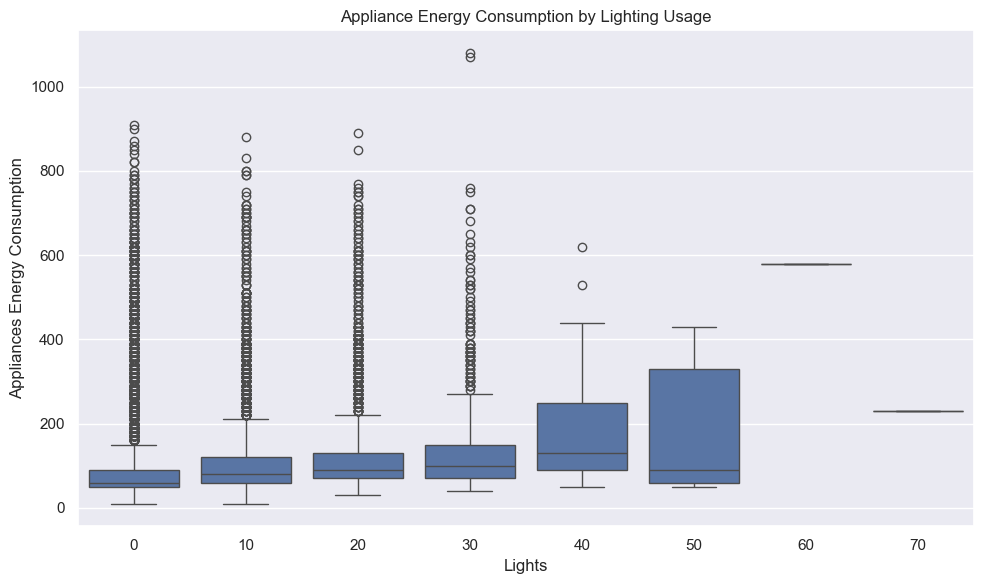

In [36]:
plt.figure(figsize=(10, 6))

sns.boxplot(x='lights',y='Appliances',data=df)
plt.title('Appliance Energy Consumption by Lighting Usage')
plt.xlabel('Lights')
plt.ylabel('Appliances Energy Consumption')
plt.tight_layout()
plt.show()

In [17]:
df.groupby('lights')['Appliances'].agg(['count','mean','median','std','max','min'])

,count,mean,median,std,max,min
lights,,,,,,
0,15252,86.584710,60.0,90.047233,910,10
10,2212,129.037071,80.0,127.503335,880,10
20,1624,136.428571,90.0,127.681071,890,30
30,559,150.214669,100.0,140.564493,1080,40
40,77,182.337662,130.0,128.420527,620,50
50,9,178.888889,90.0,154.632180,430,50
60,1,580.000000,580.0,NaN,580,580
70,1,230.000000,230.0,NaN,230,230


In [43]:
df[['lights', 'Appliances']].corr(method='spearman')

,lights,Appliances
lights,1.00000,0.30242
Appliances,0.30242,1.00000


In [45]:
print("Pearson:", df['Appliances'].corr(df['lights'], method='pearson'))
print("Spearman:",df['Appliances'].corr(df['lights'], method='spearman'))

Pearson: 0.1972775602062427
Spearman: 0.30241983190972127


The analysis shows a weak positive relationship between lighting usage (lights) and appliance energy consumption (Appliances). Pearson correlation is 0.1973, while Spearman correlation is 0.3024, indicating that the monotonic relationship is stronger than the linear relationship. The grouped statistics show that mean appliance consumption generally increases as lighting usage rises, from approximately 86.58 when lights are off to 182.34 at a lighting level of 40. However, the dataset is highly imbalanced across lighting levels: 15,252 observations have lights = 0, whereas only 77 have lights = 40 and just 11 observations have lighting levels of 50 or higher. Consequently, statistics for higher lighting levels are less reliable. The differences between means and medians, along with the high maximum consumption values, also suggest variability and potential outliers. Overall, lighting usage may provide some predictive information about appliance consumption, but its relationship is relatively weak and should be evaluated alongside other features and time-based patterns.

**Key findings:**
- Correlation: Weak positive linear association (Pearson = 0.1973).
- Monotonic relationship: Somewhat stronger positive association (Spearman = 0.3024).
- Trend: Mean appliance consumption generally increases with lighting usage.
- Data imbalance: Most observations have zero lighting usage.
- Reliability: Higher lighting categories have very small sample sizes.
- Forecasting implication: Lighting may be a useful predictor, but its independent predictive value needs further evaluation.

#### Kitchen temperature (T1) vs appliance energy consumption (Appliances)

<Axes: xlabel='T1', ylabel='Appliances'>

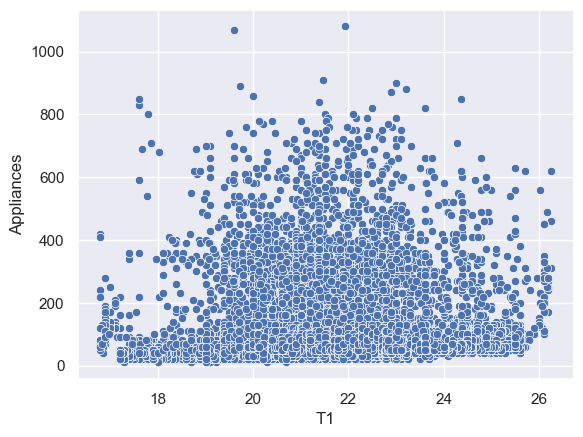

In [75]:
sns.scatterplot(y='Appliances',x='T1',data=df)

In [65]:
df.groupby(
    pd.cut(df['T1'], bins=10, include_lowest=True),
    observed=True
)['Appliances'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)

,count,mean,median,std,min,max
T1,,,,,,
"(16.779999999999998, 17.737]",172,107.732558,70.0,125.558767,10,850
"(17.737, 18.684]",413,74.188862,50.0,97.982727,10,800
"(18.684, 19.631]",1192,84.832215,50.0,114.540540,10,1070
"(19.631, 20.578]",2440,95.819672,50.0,110.761945,10,890
"(20.578, 21.525]",5356,94.831964,60.0,100.643632,10,910
"(21.525, 22.472]",4580,96.578603,60.0,98.088620,20,1080
"(22.472, 23.419]",2897,108.684846,70.0,104.878398,20,900
"(23.419, 24.366]",1193,106.362112,70.0,101.791056,20,850
"(24.366, 25.313]",1211,93.674649,60.0,80.677646,40,660


In [58]:

df[['Appliances','T1']].corr(method='spearman')

,Appliances,T1
Appliances,1.000000,0.244049
T1,0.244049,1.000000


In [60]:
df[['Appliances','T1']].corr(method='pearson')

,Appliances,T1
Appliances,1.000000,0.055447
T1,0.055447,1.000000


In [62]:
print("Pearson:", df['Appliances'].corr(df['T1'], method='pearson'))
print("Spearman:",df['Appliances'].corr(df['T1'], method='spearman'))

Pearson: 0.05544747185203625
Spearman: 0.24404899103372413


#### Weak linear relationship: Pearson correlation of 0.0554 indicates almost no linear association between kitchen temperature (T1) and appliance energy consumption.



Weak positive monotonic relationship: Spearman correlation of 0.2440 suggests that higher kitchen temperatures tend to be associated with higher appliance consumption in terms of ranks, although the relationship is weak.



Fluctuating consumption: Grouped statistics show that mean appliance consumption varies across temperature intervals rather than following a consistent upward or downward trend.



Higher consumption at the warmest interval: The mean reaches 136.94 in the highest temperature group (25.313–26.26°C), compared with 93.67 in the preceding interval.



Substantial variability: Standard deviations range from approximately 80.68 to 125.56, indicating considerable variation in consumption within temperature groups.



Uneven group sizes: Group counts range from 172 to 5,356, so statistics from smaller groups should be interpreted cautiously.



Limited standalone predictive value: Kitchen temperature alone appears to have a weak relationship with appliance consumption, but it may still contribute useful information alongside other features.

#### Appliances vs T2

In [69]:
print("Pearson:", df['Appliances'].corr(df['T2'], method='pearson'))
print("Spearman:",df['Appliances'].corr(df['T2'], method='spearman'))

Pearson: 0.12007328289803093
Spearman: 0.30509131326340827


<Axes: xlabel='T2', ylabel='Appliances'>

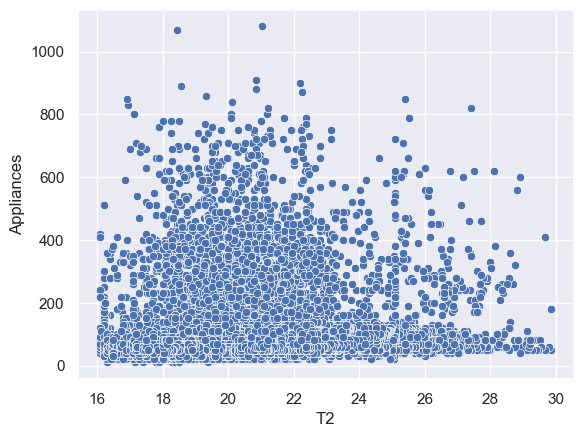

In [73]:
sns.scatterplot(y='Appliances',x='T2',data=df)

In [77]:
df.groupby(
    pd.cut(df['T2'], bins=10, include_lowest=True),
    observed=True
)['Appliances'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)

,count,mean,median,std,min,max
T2,,,,,,
"(16.084999999999997, 17.476]",1158,72.556131,50.0,85.668018,10,850
"(17.476, 18.851]",3860,78.398964,50.0,93.164829,10,1070
"(18.851, 20.227]",5742,97.380704,60.0,101.470984,10,860
"(20.227, 21.603]",4305,106.006969,70.0,106.341514,20,1080
"(21.603, 22.978]",2266,116.804943,80.0,113.785492,20,900
"(22.978, 24.354]",1284,96.238318,70.0,81.520675,20,750
"(24.354, 25.73]",625,117.712000,80.0,118.324495,20,850
"(25.73, 27.105]",330,122.848485,80.0,109.159854,30,630
"(27.105, 28.481]",126,141.666667,80.0,136.051461,50,820


#### Key Findings: Appliances vs T2
- Weak positive linear relationship: Pearson correlation is 0.1201, indicating a weak linear association between living-room temperature (T2) and appliance energy consumption.
- Stronger monotonic relationship: Spearman correlation is 0.3051, suggesting a weak positive monotonic association that is stronger than the linear relationship.
- Generally increasing consumption: Mean appliance consumption rises from 72.56 in the lowest temperature interval to 144.62 in the highest interval.
- Non-consistent trend: Mean consumption drops from 116.80 to 96.24 in the 22.978–24.354°C interval before increasing again, indicating fluctuations across temperature ranges.
- High variability: Standard deviations range from approximately 81.52 to 140.82, showing substantial variation in appliance consumption within temperature groups.
- Uneven group sizes: Counts range from 39 to 5,742 observations. The highest temperature intervals contain fewer observations, so their mean values are less stable.
- Limited standalone predictive power: Despite the overall positive trend, T2 alone has a weak correlation with appliance consumption and should be assessed alongside other predictors.

#### Appliances vs T3

In [81]:
print("Pearson:", df['Appliances'].corr(df['T3'], method='pearson'))
print("Spearman:",df['Appliances'].corr(df['T3'], method='spearman'))

Pearson: 0.08505990236567885
Spearman: 0.21685183024923813


<Axes: xlabel='T3', ylabel='Appliances'>

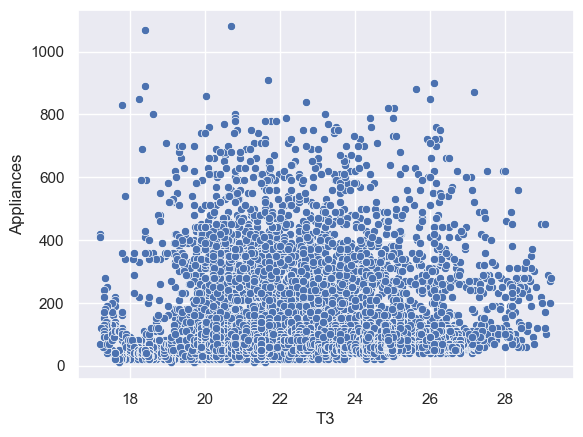

In [83]:
sns.scatterplot(x='T3',y='Appliances',data=df)

In [87]:
df.groupby(
    pd.cut(df['T3'], bins=10, include_lowest=True),
    observed=True
)['Appliances'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)

,count,mean,median,std,min,max
T3,,,,,,
"(17.186999999999998, 18.404]",345,92.260870,50.0,123.526625,10,1070
"(18.404, 19.607]",778,94.884319,50.0,123.099397,10,800
"(19.607, 20.811]",4003,88.161379,50.0,101.093556,10,1080
"(20.811, 22.014]",4455,95.730640,60.0,99.308336,10,910
"(22.014, 23.218]",4918,93.025620,60.0,87.471404,20,840
"(23.218, 24.422]",2210,111.113122,70.0,112.091241,20,790
"(24.422, 25.625]",1495,106.274247,70.0,102.505910,20,820
"(25.625, 26.829]",1277,105.293657,60.0,114.137130,40,900
"(26.829, 28.032]",170,167.705882,105.0,148.897433,40,870


#### Key Findings: Appliances vs T3
- Weak linear relationship: Pearson correlation is 0.0851, indicating a very weak positive linear association between T3 (living-room? No, T3 is the temperature in the living room? In this dataset, T3 is living room? Let's avoid unsupported labeling) temperature and appliance energy consumption.
- Weak positive monotonic relationship: Spearman correlation is 0.2169, suggesting a weak positive association in the ranks of the two variables.
- Fluctuating consumption at lower and middle temperatures: Mean appliance consumption varies between approximately 88 and 96 across several intervals, rather than increasing consistently.
- Higher means at warmer temperatures: Mean consumption rises to 111.11 in the 23.218–24.422°C interval and reaches 215.00 in the highest interval (28.032–29.236°C).
- Small high-temperature groups: The two warmest intervals contain only 170 and 84 observations, respectively, so their means may be sensitive to individual high-consumption observations.
- High variability and potential outliers: Standard deviation reaches 225.00 in the highest interval, while the maximum consumption is 560. This indicates substantial variation within that group.
- Limited standalone association: Both correlations are weak, so T3 alone has a limited relationship with appliance consumption.

#### Appliances vs T4

In [95]:
print('Pearson:',df['Appliances'].corr(df['T4']))
print('Spearman:',df['Appliances'].corr(df['T4'],method='spearman'))


Pearson: 0.04028098301092859
Spearman: 0.20715297817818928


<Axes: xlabel='T4', ylabel='Appliances'>

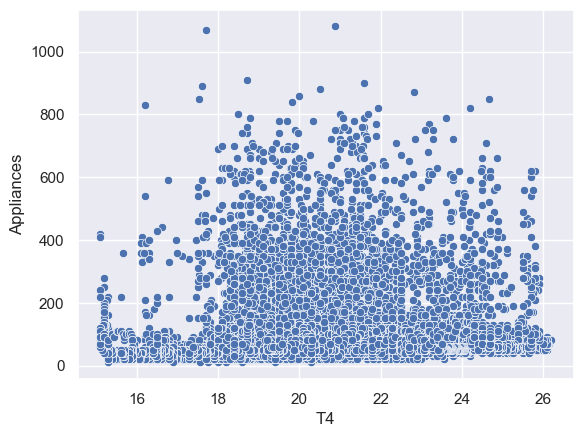

In [97]:
sns.scatterplot(x='T4',y='Appliances',data=df)

In [99]:
df.groupby(
    pd.cut(df['T4'], bins=10, include_lowest=True),
    observed=True
)['Appliances'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)

,count,mean,median,std,min,max
T4,,,,,,
"(15.088000000000001, 16.21]",279,81.577061,50.0,90.619493,10,830
"(16.21, 17.32]",403,63.498759,50.0,67.874019,10,590
"(17.32, 18.43]",1228,88.078176,50.0,115.000671,10,1070
"(18.43, 19.54]",3047,98.815228,60.0,113.125220,10,910
"(19.54, 20.65]",4906,94.626987,60.0,97.171588,10,880
"(20.65, 21.76]",4058,105.746673,70.0,109.437114,20,1080
"(21.76, 22.87]",2334,96.083976,60.0,92.522417,20,870
"(22.87, 23.98]",1791,97.666108,60.0,93.067658,20,790
"(23.98, 25.09]",1073,112.488350,80.0,105.908719,30,850


#### Key Findings: Appliances vs T4
- Almost no linear relationship: Pearson correlation is 0.0403, indicating a negligible positive linear association between T4 and appliance energy consumption.
- Weak positive monotonic relationship: Spearman correlation is 0.2072, suggesting a weak positive association based on ranks.
- Fluctuating mean consumption: Mean appliance consumption ranges from 63.50 to 112.49 across the temperature intervals, with no consistent upward or downward trend.
- Higher mean in one warmer interval: The mean reaches 112.49 in the 23.98–25.09°C interval, then falls to 92.81 in the highest interval.
- Substantial variability: Standard deviations range from approximately 67.87 to 115.00, indicating considerable variation in appliance consumption within temperature groups.
- Uneven sample sizes: Group counts range from 279 to 4,906 observations, so smaller groups may produce less stable estimates.
- Limited standalone predictive relationship: Both correlations are weak, suggesting that T4 alone has little association with appliance consumption.

#### Appliances vs T5

In [118]:
print('Pearson:',df['Appliances'].corr(df['T5']))
print('Spearman:',df['Appliances'].corr(df['T5'],method='spearman'))


Pearson: 0.019759860588739308
Spearman: 0.1858461559791062


In [111]:
df.groupby(
    pd.cut(df['T5'], bins=10, include_lowest=True),
    observed=True
)['Appliances'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)

,count,mean,median,std,min,max
T5,,,,,,
"(15.319, 16.376]",407,106.756757,50.0,135.233049,10,850
"(16.376, 17.423]",1375,86.843636,50.0,109.030067,10,910
"(17.423, 18.47]",3941,105.861456,60.0,117.656905,10,1070
"(18.47, 19.516]",4765,90.898216,60.0,95.536133,10,1080
"(19.516, 20.562]",3981,90.313991,60.0,87.992844,20,880
"(20.562, 21.609]",2801,106.419136,70.0,103.325049,20,900
"(21.609, 22.656]",668,124.625749,80.0,127.479348,20,850
"(22.656, 23.702]",1041,96.397695,70.0,80.725028,30,630
"(23.702, 24.748]",722,92.520776,60.0,81.555714,40,660


<Axes: xlabel='T5', ylabel='Appliances'>

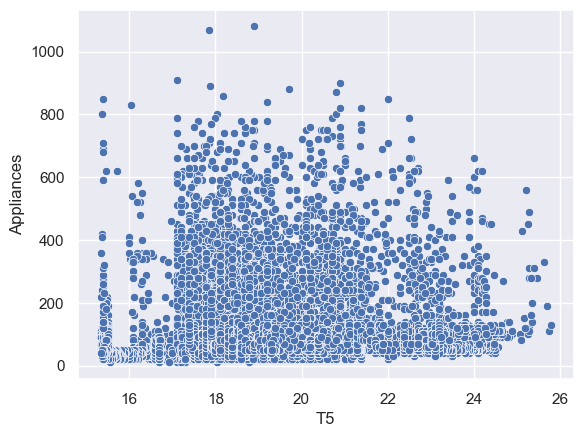

In [109]:
sns.scatterplot(x='T5',y='Appliances',data=df)

#### Key Findings: Appliances vs T5
- Negligible linear relationship: Pearson correlation is 0.0403, indicating almost no linear association between T5 and appliance energy consumption. 
- Weak positive monotonic relationship: Spearman correlation is 0.2072, suggesting a weak positive rank-based association, subject to the same verification.
- Fluctuating mean consumption: Mean appliance consumption varies across temperature intervals, ranging from 86.84 to 124.63 among the first nine groups, without a consistent increasing or decreasing trend.
- High mean in the warmest interval: The mean reaches 200.00 in the 24.748–25.795°C interval, but this group contains only 34 observations, making its estimate less reliable.
- Substantial variability: Standard deviations range from approximately 80.73 to 140.00, indicating considerable variation in consumption within groups.
- Uneven group sizes: Counts range from 34 to 4,765 observations, so results from smaller groups should be interpreted cautiously.
- Limited standalone association: If the correlation values are confirmed, T5 has little linear association with appliance consumption and only a weak monotonic association.

#### Appliances vs T6

In [116]:
print('Pearson:',df['Appliances'].corr(df['T6']))
print('Spearman:',df['Appliances'].corr(df['T6'],method='spearman'))


Pearson: 0.11763768942238197
Spearman: 0.2424768238156844


In [120]:
df.groupby(
    pd.cut(df['T6'], bins=10, include_lowest=True),
    observed=True
)['Appliances'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)

,count,mean,median,std,min,max
T6,,,,,,
"(-6.1000000000000005, -2.63]",445,85.707865,50.0,114.391280,10,740
"(-2.63, 0.806]",1510,75.509934,50.0,92.233739,20,1080
"(0.806, 4.241]",3809,84.339722,60.0,88.638992,10,860
"(4.241, 7.677]",4618,100.045474,60.0,104.158177,10,910
"(7.677, 11.112]",4295,96.454016,60.0,100.118112,10,880
"(11.112, 14.548]",2404,107.920133,70.0,107.161774,20,870
"(14.548, 17.983]",1329,116.583898,80.0,114.352192,30,900
"(17.983, 21.419]",708,105.155367,80.0,88.650761,20,820
"(21.419, 24.854]",391,167.570332,100.0,154.531482,40,850


<Axes: xlabel='T6', ylabel='Appliances'>

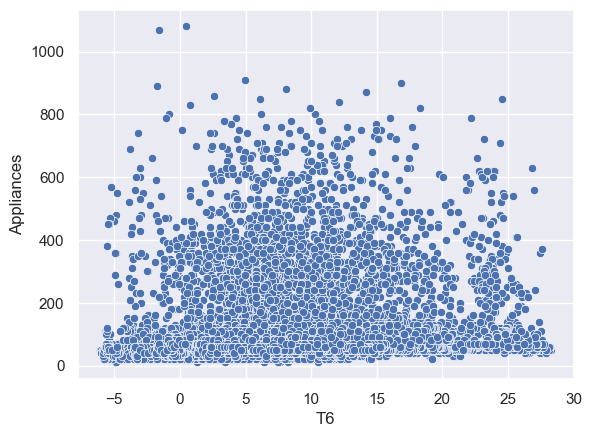

In [122]:
sns.scatterplot(x='T6',y='Appliances',data=df)

#### Key Findings: Appliances vs T6
- Weak positive linear relationship: Pearson correlation is 0.1176, indicating a weak positive linear association between T6 (outdoor temperature) and appliance energy consumption.
- Weak positive monotonic relationship: Spearman correlation is 0.2425, suggesting a somewhat stronger rank-based relationship than the linear correlation captures.
- Generally increasing consumption at moderate temperatures: Mean appliance consumption rises from 75.51 in the second interval to 116.58 in the seventh interval, although the pattern is not consistently increasing.
- Non-monotonic pattern at higher temperatures: Mean consumption peaks at 167.57 in the 21.419–24.854°C interval, then falls to 106.06 in the highest interval.
- Substantial variability: Standard deviations range from approximately 86.80 to 154.53, indicating considerable variation within temperature groups.
- Uneven sample sizes: Counts range from 226 to 4,618. The higher-temperature intervals have fewer observations, so their means should be interpreted cautiously.
- Limited standalone association: Both correlations are weak, meaning T6 alone has a limited relationship with appliance consumption.

#### Appliances vs T7

In [128]:
print('Pearson:',df['Appliances'].corr(df['T7']))
print('Spearman:',df['Appliances'].corr(df['T7'],method='spearman'))

df.groupby(
    pd.cut(df['T7'], bins=10, include_lowest=True),
    observed=True
)['Appliances'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)


Pearson: 0.02580104461965569
Spearman: 0.1818756367017187


,count,mean,median,std,min,max
T7,,,,,,
"(15.378, 16.451]",619,94.394184,50.0,117.860154,10,850
"(16.451, 17.512]",875,99.474286,50.0,132.679472,10,1070
"(17.512, 18.573]",2844,90.509845,50.0,102.143335,10,910
"(18.573, 19.634]",4304,99.386617,60.0,101.579875,10,840
"(19.634, 20.695]",2990,90.220736,60.0,93.561648,20,1080
"(20.695, 21.756]",3544,97.483070,60.0,97.867971,20,820
"(21.756, 22.817]",1650,118.581818,80.0,117.786543,20,900
"(22.817, 23.878]",1685,99.020772,60.0,94.393565,20,820
"(23.878, 24.939]",1031,91.125121,60.0,86.084711,30,850


<Axes: xlabel='T7', ylabel='Appliances'>

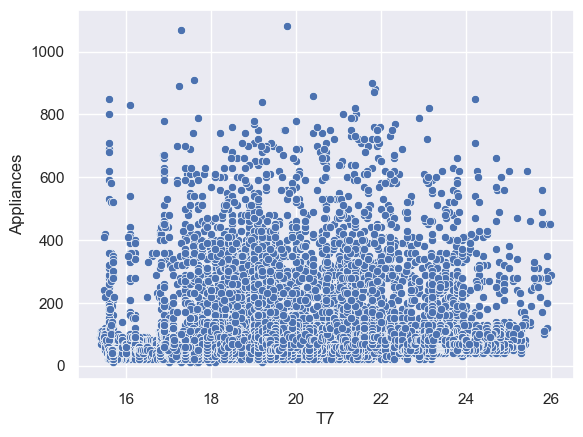

In [130]:
sns.scatterplot(x='T7',y='Appliances',data=df)

#### Key Findings: Appliances vs T7
- Negligible linear relationship: Pearson correlation is 0.0258, indicating almost no linear association between T7 and appliance energy consumption.
- Weak positive monotonic relationship: Spearman correlation is 0.1819, suggesting a weak positive rank-based association.
- Fluctuating mean consumption: Mean appliance consumption varies between approximately 90 and 119 across most temperature intervals, with no consistent increasing or decreasing pattern.
- Higher means in two intervals: Mean consumption reaches 118.58 in the 21.756–22.817°C interval and 133.01 in the highest interval (24.939–26.0°C).
- Substantial variability: Standard deviations range from approximately 86.08 to 132.68, indicating considerable variation in consumption within the groups.
- Uneven sample sizes: Counts range from 193 to 4,304 observations. The highest-temperature interval has only 193 observations, so its mean is less stable than estimates from larger groups.
- Limited standalone relationship: Both correlations are weak, suggesting that T7 alone has little association with appliance consumption.

#### Appliances vs T8

In [134]:
print('Pearson:',df['Appliances'].corr(df['T8']))
print('Spearman:',df['Appliances'].corr(df['T8'],method='spearman'))

df.groupby(
    pd.cut(df['T8'], bins=10, include_lowest=True),
    observed=True
)['Appliances'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)


Pearson: 0.0395719810955945
Spearman: 0.23614682320419672


,count,mean,median,std,min,max
T8,,,,,,
"(16.294999999999998, 17.399]",225,58.222222,40.0,48.287129,10,280
"(17.399, 18.491]",859,81.525029,50.0,117.075386,10,910
"(18.491, 19.584]",1090,95.036697,50.0,116.744360,10,1070
"(19.584, 20.676]",2389,112.637087,60.0,125.232090,10,830
"(20.676, 21.768]",3803,85.677097,60.0,90.053365,20,1080
"(21.768, 22.861]",4507,95.398269,60.0,95.819358,20,860
"(22.861, 23.953]",3708,107.508091,70.0,108.614363,20,880
"(23.953, 25.045]",2115,103.234043,70.0,92.349955,20,900
"(25.045, 26.138]",805,97.813665,70.0,85.272114,40,660


<Axes: xlabel='T8', ylabel='Appliances'>

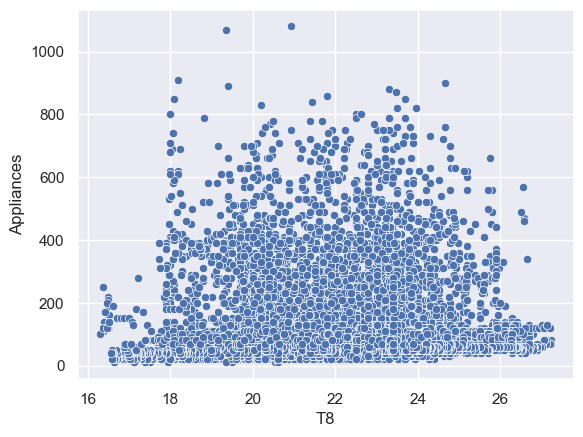

In [136]:
sns.scatterplot(x='T8',y='Appliances',data=df)

#### Key Findings: Appliances vs T8
- Negligible linear relationship: Pearson correlation is 0.0396, indicating almost no linear association between T8 and appliance energy consumption.
- Weak positive monotonic relationship: Spearman correlation is 0.2361, suggesting a weak positive rank-based association that is stronger than the linear relationship.
- Fluctuating mean consumption: Mean appliance consumption rises from 58.22 in the lowest temperature interval to 112.64 in the fourth interval, then fluctuates across the remaining intervals.
- No consistent temperature trend: Mean consumption falls to 85.68 in the fifth interval, rises to 107.51 in the seventh, and declines again at higher temperatures.
- Substantial variability: Standard deviations range from approximately 48.29 to 125.23, showing considerable variation in consumption within several groups.
- Uneven sample sizes: Counts range from 225 to 4,507 observations. The smallest groups may produce less stable mean estimates.
- Limited standalone relationship: Both correlations are weak, indicating that T8 alone has limited association with appliance consumption.

#### Appliances vs T9

In [140]:
print('Pearson:',df['Appliances'].corr(df['T9']))
print('Spearman:',df['Appliances'].corr(df['T9'],method='spearman'))

df.groupby(
    pd.cut(df['T9'], bins=10, include_lowest=True),
    observed=True
)['Appliances'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)


Pearson: 0.010010284644666278
Spearman: 0.1669763643157298


,count,mean,median,std,min,max
T9,,,,,,
"(14.879000000000001, 15.851]",433,109.399538,60.0,132.839745,10,850
"(15.851, 16.812]",1004,91.434263,50.0,119.204469,10,1070
"(16.812, 17.773]",2248,94.154804,50.0,112.688144,10,910
"(17.773, 18.734]",4335,98.041522,60.0,100.568610,10,1080
"(18.734, 19.695]",3153,98.179512,60.0,100.688541,20,860
"(19.695, 20.656]",3840,93.190104,60.0,93.123592,20,880
"(20.656, 21.617]",1703,113.746330,70.0,115.338103,20,900
"(21.617, 22.578]",564,86.294326,60.0,73.166822,20,820
"(22.578, 23.539]",1763,99.988656,70.0,95.153856,20,850


<Axes: xlabel='T9', ylabel='Appliances'>

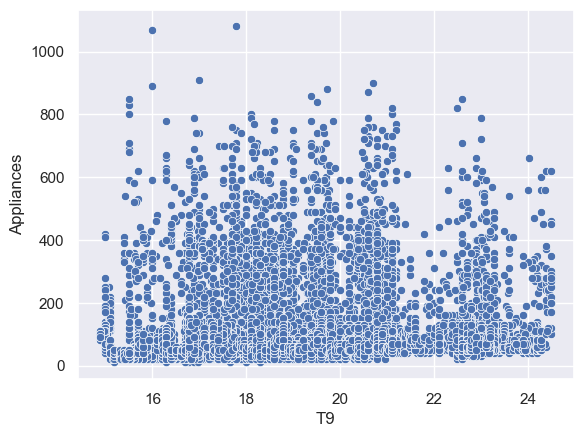

In [144]:
sns.scatterplot(x='T9',y='Appliances',data=df)

#### Key Findings: Appliances vs T9
- Pearson correlation (0.0100): Almost no linear relationship between T9 and appliance energy consumption.
- Spearman correlation (0.1670): A weak positive monotonic relationship exists, suggesting appliance consumption tends to increase slightly as T9 rises, but the relationship is not consistent.
- Grouped means fluctuate: Mean consumption ranges from approximately 86.29 Wh to 113.75 Wh across the temperature bins. It does not rise steadily with T9.
- Median consumption is relatively stable: Most bins have medians of 50–70 Wh, suggesting that typical consumption changes only modestly across these temperature ranges.
- High variability remains: Standard deviations range from about 73.17 to 132.84 Wh, and some groups contain values above 1,000 Wh. This indicates that T9 alone does not explain much of the variation in appliance consumption.
- Uneven group sizes: Some bins have substantially fewer observations than others, so their means may be less representative.

#### Appliances vs RH_1

In [148]:
print('Pearson:',df['Appliances'].corr(df['RH_1']))
print('Spearman:',df['Appliances'].corr(df['RH_1'],method='spearman'))

df.groupby(
    pd.cut(df['RH_1'], bins=10, include_lowest=True),
    observed=True
)['Appliances'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)


Pearson: 0.08603142531155081
Spearman: 0.0605189400420219


,count,mean,median,std,min,max
RH_1,,,,,,
"(26.985999999999997, 30.657]",40,92.500000,70.0,94.536657,20,540
"(30.657, 34.291]",710,107.732394,80.0,106.107227,20,860
"(34.291, 37.924]",5285,86.968780,60.0,88.932010,20,1070
"(37.924, 41.558]",6843,93.241268,60.0,95.259080,10,880
"(41.558, 45.192]",4467,107.924782,60.0,116.246398,10,1080
"(45.192, 48.825]",2006,104.730808,60.0,113.355541,10,820
"(48.825, 52.459]",301,148.737542,100.0,136.057834,40,790
"(52.459, 56.093]",75,157.066667,110.0,106.323999,50,490
"(56.093, 59.726]",7,170.000000,100.0,199.499373,50,620


<Axes: xlabel='RH_1', ylabel='Appliances'>

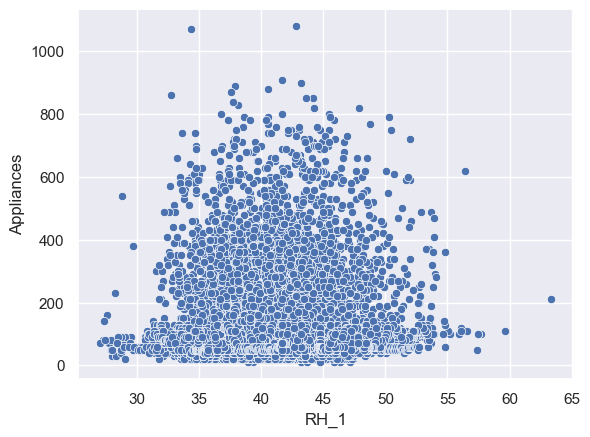

In [150]:
sns.scatterplot(x='RH_1',y='Appliances',data=df)

#### Key Findings: Appliances vs RH_1
- Pearson correlation (0.0860): There is a very weak positive linear relationship between kitchen relative humidity (RH_1) and appliance energy consumption.
- Spearman correlation (0.0605): The rank-based relationship is also very weak. Unlike several temperature features we analyzed, RH_1 does not show a meaningful monotonic relationship with appliance consumption.
- Grouped means fluctuate at lower and moderate humidity: Mean consumption drops from about 107.73 Wh in the second bin to 86.97 Wh in the third, then rises and fluctuates across the middle bins.
- Higher humidity bins show larger means: The mean reaches approximately 148.74–170 Wh in bins above 48.8% humidity. However, these bins contain far fewer observations: 301, 75, 7, and 1 respectively. These small sample sizes make the apparent increase less reliable.
- Typical consumption remains lower than some means: The median is 60 Wh in several of the larger groups, while means are higher. This suggests that occasional high-consumption observations influence the averages.
- High variability persists: Standard deviations are large in many bins, reinforcing that kitchen humidity alone does not explain appliance consumption well.

#### Appliances vs RH_2

In [154]:
print('Pearson:',df['Appliances'].corr(df['RH_2']))
print('Spearman:',df['Appliances'].corr(df['RH_2'],method='spearman'))

df.groupby(
    pd.cut(df['RH_2'], bins=10, include_lowest=True),
    observed=True
)['Appliances'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)


Pearson: -0.06046476002711875
Spearman: -0.1197356234263457


,count,mean,median,std,min,max
RH_2,,,,,,
"(20.427, 24.02]",16,83.125000,85.0,33.807051,30,160
"(24.02, 27.576]",60,88.166667,70.0,76.146417,20,540
"(27.576, 31.132]",256,110.468750,90.0,85.697685,40,630
"(31.132, 34.689]",1304,120.774540,80.0,124.163873,20,1070
"(34.689, 38.245]",3890,102.586118,70.0,103.661662,20,1080
"(38.245, 41.801]",7018,93.992590,60.0,99.316409,10,910
"(41.801, 45.358]",5327,95.734935,60.0,103.787184,10,850
"(45.358, 48.914]",1499,88.652435,60.0,93.656183,10,820
"(48.914, 52.47]",330,84.484848,60.0,73.409424,40,530


<Axes: xlabel='RH_2', ylabel='Appliances'>

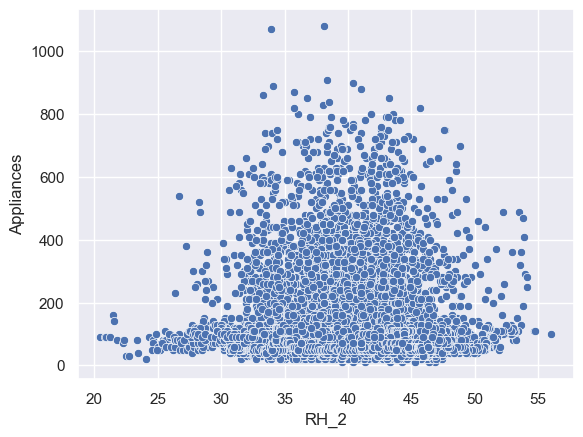

In [156]:
sns.scatterplot(x='RH_2',y='Appliances',data=df)

#### Key Findings: Appliances vs RH_2
- Pearson correlation (-0.0605): There is a very weak negative linear relationship between living-room relative humidity (RH_2) and appliance energy consumption.
- Spearman correlation (-0.1197): The negative rank-based relationship is somewhat stronger, suggesting a weak tendency for consumption to decrease as humidity increases. However, the relationship is not strong.
- Grouped means generally decline across the larger bins: Mean consumption falls from around 120.77 Wh in the 31.13–34.69% bin to approximately 84.48 Wh in the 48.91–52.47% bin. This broadly supports the weak negative correlations.
- The highest-humidity bin is an exception: Its mean is 176.29 Wh, but it contains only 35 observations. This small sample could make its mean unstable and should not be treated as evidence of a reliable reversal.
- High variability remains: Standard deviations are substantial across most bins, and some observations exceed 1,000 Wh. Relative humidity alone does not explain much of the variation in appliance consumption.
- Uneven sample sizes matter: The middle humidity bins contain most observations, while the lowest and highest bins are much smaller. Interpret their means cautiously.

#### Appliances vs RH_3

In [160]:
print('Pearson:',df['Appliances'].corr(df['RH_3']))
print('Spearman:',df['Appliances'].corr(df['RH_3'],method='spearman'))

df.groupby(
    pd.cut(df['RH_3'], bins=10, include_lowest=True),
    observed=True
)['Appliances'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)


Pearson: 0.03629172115353253
Spearman: -0.05706571716341631


,count,mean,median,std,min,max
RH_3,,,,,,
"(28.744, 30.906]",18,155.555556,110.0,138.063166,70,570
"(30.906, 33.046]",88,97.159091,70.0,92.462467,20,580
"(33.046, 35.186]",1510,102.549669,80.0,97.367891,20,860
"(35.186, 37.325]",4569,92.974393,60.0,95.873802,20,1070
"(37.325, 39.465]",5729,93.157619,60.0,95.200629,10,900
"(39.465, 41.605]",2761,102.238319,60.0,109.996323,10,1080
"(41.605, 43.744]",2345,106.733475,60.0,112.876935,10,850
"(43.744, 45.884]",2335,92.989293,50.0,107.151989,10,910
"(45.884, 48.024]",356,136.882022,90.0,134.065772,20,740


<Axes: xlabel='RH_3', ylabel='Appliances'>

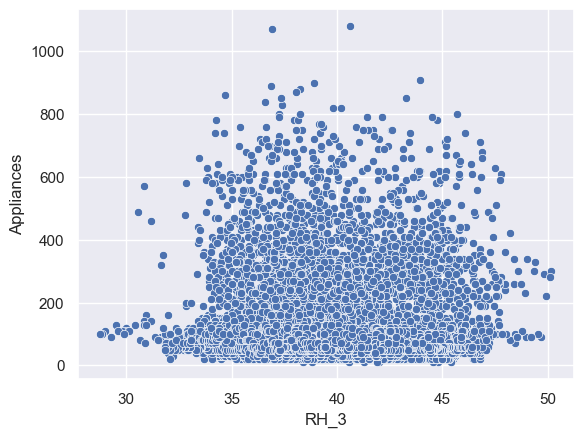

In [162]:
sns.scatterplot(x='RH_3',y='Appliances',data=df)

#### Key Findings: Appliances vs RH_3
- Pearson correlation (0.0363): There is virtually no linear relationship between laundry-room relative humidity (RH_3) and appliance energy consumption.
- Spearman correlation (-0.0571): The rank-based relationship is also negligible and slightly negative. The opposite signs of the two correlations indicate that there is no clear, consistent association.
- Grouped means fluctuate: Mean consumption falls from 102.55 Wh in the 33.05–35.19% bin to around 92.97 Wh in the next bin, then rises and falls across the remaining intervals. There is no stable upward or downward trend.
- The highest-humidity bins have larger means: The final two bins have means of 136.88 Wh and 203.33 Wh. However, they contain only 356 and 24 observations, respectively, so these values should be interpreted cautiously.
- High variability is common: Standard deviations are around 95–113 Wh in many of the larger groups, with some maximum observations exceeding 1,000 Wh. This indicates substantial variation in appliance consumption at similar humidity levels.
- Median consumption is relatively stable: Most larger groups have medians between 50 and 80 Wh, despite fluctuations in their means.

#### Appliances vs RH_4 

In [166]:
print('Pearson:',df['Appliances'].corr(df['RH_4']))
print('Spearman:',df['Appliances'].corr(df['RH_4'],method='spearman'))

df.groupby(
    pd.cut(df['RH_4'], bins=10, include_lowest=True),
    observed=True
)['Appliances'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)


Pearson: 0.016965431418944958
Spearman: -0.02023312570962877


,count,mean,median,std,min,max
RH_4,,,,,,
"(27.636, 30.003]",35,105.142857,90.0,85.830593,20,540
"(30.003, 32.346]",422,128.270142,80.0,129.305079,20,860
"(32.346, 34.689]",2815,93.939609,60.0,92.710526,20,870
"(34.689, 37.032]",4161,95.551550,60.0,99.425222,10,1070
"(37.032, 39.375]",4201,90.257082,60.0,95.650557,10,880
"(39.375, 41.718]",2765,105.790235,70.0,106.127395,10,1080
"(41.718, 44.061]",2104,107.923004,60.0,117.187730,10,910
"(44.061, 46.404]",1997,94.116174,60.0,101.842655,10,850
"(46.404, 48.747]",932,88.937768,50.0,103.627278,10,790


<Axes: xlabel='RH_4', ylabel='Appliances'>

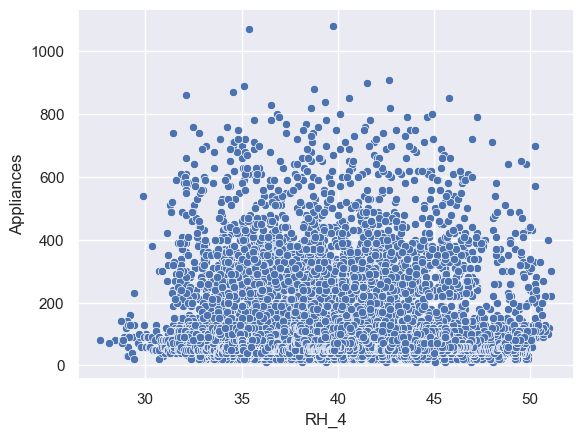

In [168]:
sns.scatterplot(x='RH_4',y='Appliances',data=df)

#### Key Findings: Appliances vs RH_4
- Pearson correlation (0.0170): There is virtually no linear relationship between office relative humidity (RH_4) and appliance energy consumption.
- Spearman correlation (-0.0202): The rank-based relationship is also negligible and slightly negative. Both correlations are close to zero, indicating no meaningful overall association.
- Grouped means fluctuate considerably: Mean consumption ranges from about 88.94 Wh to 128.27 Wh across the bins, with no consistent upward or downward trend.
- Middle humidity ranges show mixed patterns: Mean consumption decreases across several bins, rises around 39.38–44.06%, and then falls again at higher humidity levels.
- The highest-humidity bin has a higher mean: Its mean is approximately 127.33 Wh, but it contains only 303 observations. The second bin also has a high mean (128.27 Wh) with 422 observations, so neither establishes a consistent trend.
- Substantial variability remains: Standard deviations are approximately 93–129 Wh in most groups, and maximum consumption reaches 1,080 Wh. Similar humidity levels can therefore correspond to very different appliance consumption values.

#### Appliances vs RH_5

In [172]:
print('Pearson:',df['Appliances'].corr(df['RH_5']))
print('Spearman:',df['Appliances'].corr(df['RH_5'],method='spearman'))

df.groupby(
    pd.cut(df['RH_5'], bins=10, include_lowest=True),
    observed=True
)['Appliances'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)


Pearson: 0.0069545362624179536
Spearman: -0.04490356530631796


,count,mean,median,std,min,max
RH_5,,,,,,
"(29.747, 36.466]",43,106.511628,60.0,105.059705,40,540
"(36.466, 43.116]",2372,102.618044,70.0,106.044725,10,1070
"(43.116, 49.767]",8196,99.898731,60.0,103.898397,10,900
"(49.767, 56.418]",5937,95.349503,60.0,107.048352,10,1080
"(56.418, 63.068]",1550,76.909677,60.0,72.774479,10,670
"(63.068, 69.719]",606,85.346535,60.0,70.353032,20,590
"(69.719, 76.37]",366,115.737705,80.0,108.319047,20,690
"(76.37, 83.02]",361,114.099723,90.0,90.819302,30,610
"(83.02, 89.671]",233,143.047210,100.0,124.494434,20,740


<Axes: xlabel='RH_5', ylabel='Appliances'>

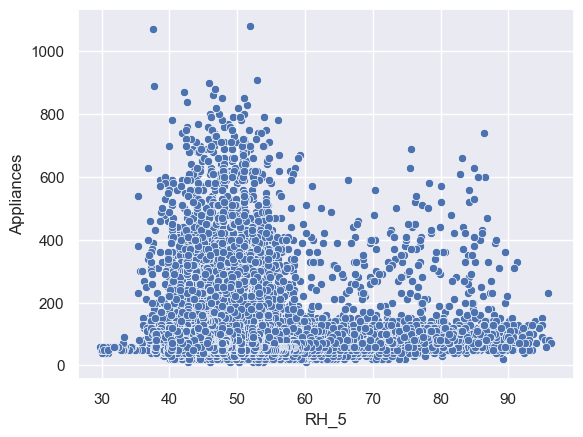

In [174]:
sns.scatterplot(x='RH_5',y='Appliances',data=df)

#### Key Findings: Appliances vs RH_5
- Pearson correlation (0.0070): There is virtually no linear relationship between bathroom relative humidity (RH_5) and appliance energy consumption.
- Spearman correlation (-0.0449): The rank-based relationship is also negligible and slightly negative. Neither correlation suggests a meaningful overall association.
- Mean consumption initially declines: Across the larger bins, mean consumption falls from approximately 102.62 Wh at 36.47–43.12% humidity to 76.91 Wh at 56.42–63.07%.
- Higher-humidity bins fluctuate: Mean consumption rises to around 115–143 Wh in several higher-humidity bins, but those groups have fewer observations. The pattern does not establish a consistent relationship.
- Median consumption is relatively stable: The larger groups generally have medians of 60–70 Wh, even when their means differ. This suggests that higher-consumption observations influence some group averages.
- Variability and sample size matter: Standard deviations vary substantially, and the highest-humidity bin contains only 71 observations. Interpret the upper-bin means cautiously.

#### Appliances vs RH_6

In [178]:
print('Pearson:',df['Appliances'].corr(df['RH_6']))
print('Spearman:',df['Appliances'].corr(df['RH_6'],method='spearman'))

df.groupby(
    pd.cut(df['RH_6'], bins=10, include_lowest=True),
    observed=True
)['Appliances'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)


Pearson: -0.08317760704200428
Spearman: -0.22973400015243484


,count,mean,median,std,min,max
RH_6,,,,,,
"(0.9, 10.89]",2517,126.154152,90.0,116.854597,20,870
"(10.89, 20.78]",1183,115.579036,70.0,122.650434,20,900
"(20.78, 30.67]",1338,101.659193,70.0,98.162309,20,720
"(30.67, 40.56]",1595,98.156740,70.0,85.842861,20,780
"(40.56, 50.45]",1792,87.650670,60.0,86.299989,20,880
"(50.45, 60.34]",2456,77.109121,60.0,74.648599,20,860
"(60.34, 70.23]",1511,86.532098,60.0,92.248686,20,780
"(70.23, 80.12]",1702,100.611046,60.0,112.055680,20,910
"(80.12, 90.01]",2313,88.495460,50.0,97.167863,10,770


<Axes: xlabel='RH_6', ylabel='Appliances'>

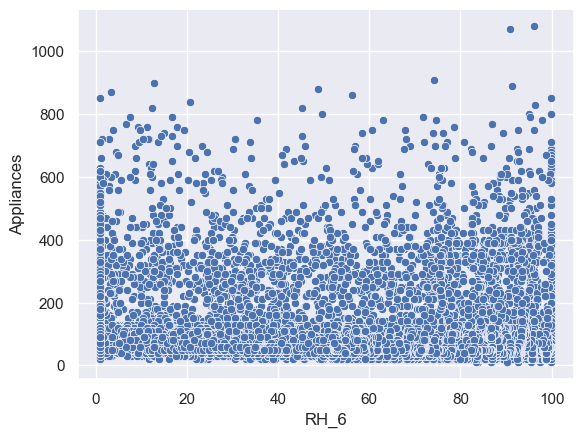

In [180]:
sns.scatterplot(x='RH_6',y='Appliances',data=df)

#### Key Findings: Appliances vs RH_6
- Pearson correlation (-0.0832): There is a weak negative linear relationship between outdoor relative humidity (RH_6) and appliance energy consumption.
- Spearman correlation (-0.2297): The negative rank-based relationship is more noticeable, suggesting a weak tendency for appliance consumption to decrease as outdoor humidity increases. The association is still not strong.
- Grouped means show a broad decline at first: Mean consumption falls from 126.15 Wh in the lowest humidity bin to 77.11 Wh in the 50.45–60.34% bin. This broadly supports the negative correlations.
- The relationship is not consistently decreasing: Mean consumption rises again in several higher-humidity bins, reaching 100.61 Wh in the 70.23–80.12% interval. This suggests a non-linear or context-dependent pattern.
- Median consumption also tends to decline: The median drops from 90 Wh in the lowest bin to around 50–60 Wh in many later bins, supporting a broad negative tendency.
- High variability remains: Standard deviations range from about 74.65 to 122.65 Wh, and the highest observed consumption is 1,080 Wh. Outdoor humidity alone cannot explain individual consumption levels.

#### Appliances vs RH_7

In [184]:
print('Pearson:',df['Appliances'].corr(df['RH_7']))
print('Spearman:',df['Appliances'].corr(df['RH_7'],method='spearman'))

df.groupby(
    pd.cut(df['RH_7'], bins=10, include_lowest=True),
    observed=True
)['Appliances'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)


Pearson: -0.055642418336332156
Spearman: -0.11940891829644659


,count,mean,median,std,min,max
RH_7,,,,,,
"(23.171, 26.02]",368,159.782609,100.0,145.054557,20,760
"(26.02, 28.84]",1427,103.062369,80.0,100.729866,20,1070
"(28.84, 31.66]",3371,104.603975,70.0,104.910229,20,870
"(31.66, 34.48]",4108,92.448880,60.0,96.206554,10,840
"(34.48, 37.3]",3534,94.572722,60.0,97.678842,10,1080
"(37.3, 40.12]",2919,99.534087,60.0,109.495645,10,910
"(40.12, 42.94]",2305,89.696312,60.0,100.760966,10,850
"(42.94, 45.76]",1397,92.634216,60.0,97.858540,10,790
"(45.76, 48.58]",224,102.633929,60.0,101.706206,20,650


<Axes: xlabel='RH_7', ylabel='Appliances'>

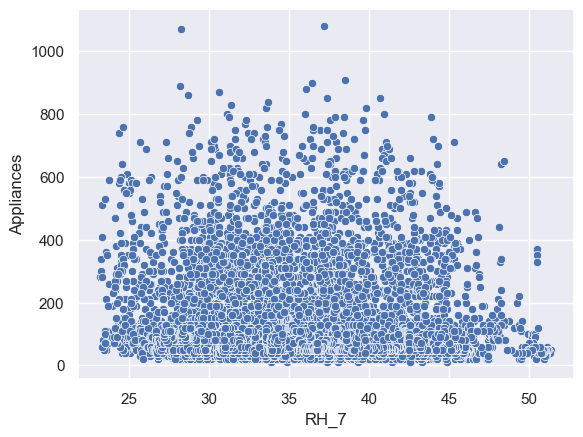

In [186]:
sns.scatterplot(x='RH_7',y='Appliances',data=df)

#### Key Findings: Appliances vs RH_7
- Pearson correlation (-0.0556): There is a very weak negative linear relationship between ironing-room relative humidity (RH_7) and appliance energy consumption.
- Spearman correlation (-0.1194): The rank-based relationship is also weakly negative, suggesting a slight tendency for consumption to decrease as humidity rises.
- Grouped means generally decline from the lowest bin: Mean consumption falls from 159.78 Wh in the lowest bin to around 92–95 Wh in several middle bins. This broadly agrees with the negative correlations.
- The trend is not consistent: Mean consumption fluctuates across the middle bins, rises to 102.63 Wh in the 45.76–48.58% bin, and then falls to 71.10 Wh in the highest bin.
- The lowest bin has a high mean: Its mean is 159.78 Wh, but the median is 100 Wh and the standard deviation is 145.05 Wh, indicating considerable variation. This bin contains 368 observations, so the result is more informative than a tiny group but still should not be overinterpreted.
- High variability remains: Many bins have standard deviations near 97–110 Wh. Relative humidity alone does not explain much of the variation in appliance consumption.

#### Appliances vs RH_8

In [190]:
print('Pearson:',df['Appliances'].corr(df['RH_8']))
print('Spearman:',df['Appliances'].corr(df['RH_8'],method='spearman'))

df.groupby(
    pd.cut(df['RH_8'], bins=10, include_lowest=True),
    observed=True
)['Appliances'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)


Pearson: -0.09403862707398902
Spearman: -0.21723626477470007


,count,mean,median,std,min,max
RH_8,,,,,,
"(29.57, 32.518]",184,172.391304,100.0,155.780212,40,710
"(32.518, 35.436]",919,117.007617,80.0,113.578507,20,760
"(35.436, 38.354]",2864,111.305866,80.0,102.201605,20,1070
"(38.354, 41.272]",4299,99.278902,60.0,101.968029,20,880
"(41.272, 44.19]",4126,92.317014,60.0,98.068435,10,1080
"(44.19, 47.108]",2830,88.890459,60.0,98.884403,10,910
"(47.108, 50.026]",2289,95.312363,60.0,104.807102,10,780
"(50.026, 52.944]",1515,94.330033,60.0,105.527532,10,850
"(52.944, 55.862]",620,71.903226,50.0,81.478207,10,620


<Axes: xlabel='RH_8', ylabel='Appliances'>

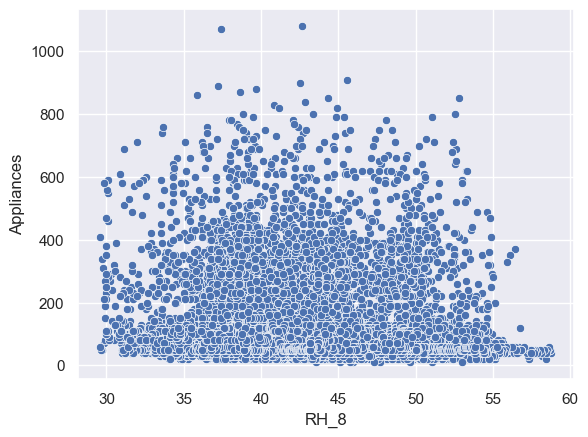

In [192]:
sns.scatterplot(x='RH_8',y='Appliances',data=df)

#### Key Findings: Appliances vs RH_8
- Pearson correlation (-0.0940): There is a weak negative linear relationship between relative humidity in the teenager's room (RH_8) and appliance energy consumption.
- Spearman correlation (-0.2172): The negative rank-based relationship is more noticeable, indicating that consumption tends to decrease as humidity increases, although the association remains weak.
- Grouped means show a clearer downward pattern: Mean consumption declines from 172.39 Wh in the lowest humidity bin to 88.89 Wh in the 44.19–47.11% bin.
- The decline continues at higher humidity levels: Mean consumption falls to 71.90 Wh and then 56.85 Wh in the final two bins. These groups contain 620 and 89 observations, respectively, so the last bin deserves caution.
- The relationship is not perfectly monotonic: Mean consumption rises slightly in the 47.11–50.03% bin before declining again.
- High variability remains: Standard deviations are substantial in most bins, especially at lower humidity levels. This means humidity alone does not explain individual appliance consumption reliably.

#### Appliances vs RH_9

In [196]:
print('Pearson:',df['Appliances'].corr(df['RH_9']))
print('Spearman:',df['Appliances'].corr(df['RH_9'],method='spearman'))

df.groupby(
    pd.cut(df['RH_9'], bins=10, include_lowest=True),
    observed=True
)['Appliances'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)


Pearson: -0.05146201134630323
Spearman: -0.16455341819611372


,count,mean,median,std,min,max
RH_9,,,,,,
"(29.142, 31.583]",73,148.356164,100.0,135.226289,40,580
"(31.583, 33.999]",269,103.159851,100.0,58.794295,30,460
"(33.999, 36.415]",1184,102.854730,80.0,86.005322,20,830
"(36.415, 38.831]",4053,109.096965,70.0,112.497554,20,1070
"(38.831, 41.247]",5019,90.862722,60.0,94.269616,20,1080
"(41.247, 43.663]",3412,97.025205,60.0,105.463901,10,910
"(43.663, 46.079]",2206,98.544878,60.0,103.921803,20,820
"(46.079, 48.495]",2072,100.670849,60.0,109.357386,10,790
"(48.495, 50.911]",1239,76.037127,50.0,93.872195,10,850


<Axes: xlabel='RH_9', ylabel='Appliances'>

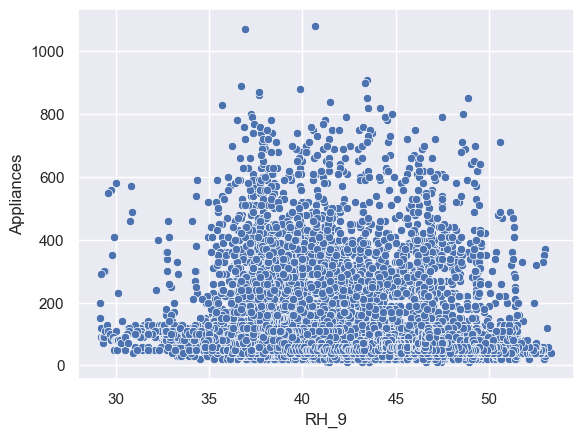

In [198]:
sns.scatterplot(x='RH_9',y='Appliances',data=df)

#### Key Findings: Appliances vs RH_9
- Pearson correlation (-0.0515): There is a very weak negative linear relationship between parents' room relative humidity (RH_9) and appliance energy consumption.
- Spearman correlation (-0.1646): The negative rank-based relationship is somewhat stronger, suggesting a weak tendency for consumption to decrease as humidity rises.
- Grouped means fluctuate: Mean consumption is relatively high in the lower humidity bins, drops to 90.86 Wh in the 38.83–41.25% bin, rises slightly across several middle bins, and then falls to 76.04 Wh in the 48.50–50.91% bin.
- The highest-humidity bin does not continue the decline: Its mean is 87.50 Wh, compared with 76.04 Wh in the preceding bin. This confirms that the relationship is not consistently decreasing.
- The first bin has a high mean: Its mean is 148.36 Wh, but it contains only 73 observations and has a standard deviation of 135.23 Wh. This makes the result less stable.
- High variability persists: Most larger groups have standard deviations around 94–112 Wh, indicating that RH_9 alone does not explain much of the variation in appliance consumption.

#### Appliances vs T_out

In [204]:
print('Pearson:',df['Appliances'].corr(df['T_out']))
print('Spearman:',df['Appliances'].corr(df['T_out'],method='spearman'))

df.groupby(
    pd.cut(df['T_out'], bins=10, include_lowest=True),
    observed=True
)['Appliances'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)


Pearson: 0.09915465073995954
Spearman: 0.21550392442370148


,count,mean,median,std,min,max
T_out,,,,,,
"(-5.032, -1.89]",441,81.337868,50.0,114.315260,10,740
"(-1.89, 1.22]",1731,74.269209,50.0,84.600218,10,1070
"(1.22, 4.33]",3600,90.641667,60.0,95.964732,10,1080
"(4.33, 7.44]",4823,101.138296,60.0,106.312627,10,910
"(7.44, 10.55]",4385,96.394527,60.0,99.562567,10,880
"(10.55, 13.66]",2328,106.469072,60.0,110.549621,10,870
"(13.66, 16.77]",1370,108.284672,70.0,99.744264,30,900
"(16.77, 19.88]",568,108.098592,80.0,100.950915,20,790
"(19.88, 22.99]",357,153.865546,100.0,132.245787,40,850


<Axes: xlabel='T_out', ylabel='Appliances'>

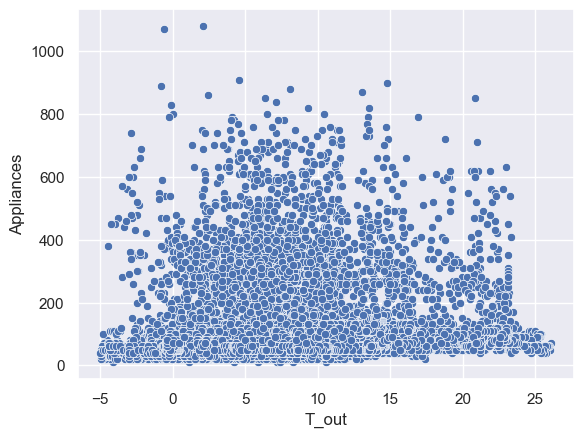

In [206]:
sns.scatterplot(x='T_out',y='Appliances',data=df)

#### Key Findings: Appliances vs T_out
- Pearson correlation (0.0992): There is a weak positive linear relationship between outdoor temperature (T_out) and appliance energy consumption.
- Spearman correlation (0.2155): The positive rank-based relationship is more noticeable, suggesting that appliance consumption tends to increase as outdoor temperature rises, although the association remains weak.
- Grouped means generally rise from colder to moderate temperatures: Mean consumption increases from around 74–81 Wh in the two coldest bins to approximately 101–108 Wh across several middle and warmer bins.
- The trend is not consistent at the warmest temperatures: Mean consumption peaks at 153.87 Wh in the 19.88–22.99°C bin, then falls to 107.95 Wh in the warmest bin. The peak bin contains 357 observations, while the warmest contains 132, so these averages should be interpreted cautiously.
- Median consumption increases modestly: The median rises from 50 Wh in the colder bins to 70–100 Wh in several warmer bins, broadly supporting the positive rank-based association.
- High variability remains: Standard deviations are approximately 85–132 Wh across the bins, showing that outdoor temperature alone cannot explain appliance consumption.

In [209]:
df.columns

Index(['date', 'Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3',
       'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8',
       'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed',
       'Visibility', 'Tdewpoint', 'rv1', 'rv2'],
      dtype='object')

#### Appliances vs Press_mm_hg

In [212]:
print('Pearson:',df['Appliances'].corr(df['Press_mm_hg']))
print('Spearman:',df['Appliances'].corr(df['Press_mm_hg'],method='spearman'))

df.groupby(
    pd.cut(df['Press_mm_hg'], bins=10, include_lowest=True),
    observed=True
)['Appliances'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)


Pearson: -0.034884829081635316
Spearman: -0.0961756476120789


,count,mean,median,std,min,max
Press_mm_hg,,,,,,
"(729.256, 733.6]",116,122.413793,90.0,107.222813,30,560
"(733.6, 737.9]",186,139.139785,100.0,120.903409,30,690
"(737.9, 742.2]",681,99.911894,60.0,103.683588,20,750
"(742.2, 746.5]",1183,92.273880,60.0,90.490220,20,800
"(746.5, 750.8]",2673,110.404040,70.0,112.831288,20,910
"(750.8, 755.1]",4064,93.277559,60.0,92.955867,10,780
"(755.1, 759.4]",4484,94.788136,60.0,101.532863,10,880
"(759.4, 763.7]",3335,96.581709,60.0,102.619897,10,830
"(763.7, 768.0]",2476,95.924879,60.0,109.018360,10,1080


<Axes: xlabel='Press_mm_hg', ylabel='Appliances'>

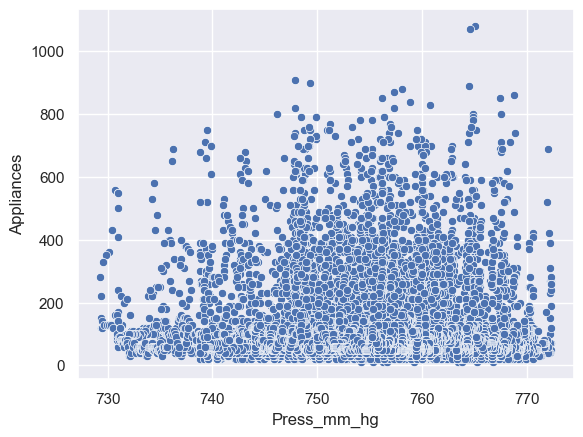

In [214]:
sns.scatterplot(x='Press_mm_hg',y='Appliances',data=df)

#### Key Findings: Appliances vs Press_mm_hg
- Pearson correlation (-0.0349): There is virtually no linear relationship between atmospheric pressure (Press_mm_hg) and appliance energy consumption.
- Spearman correlation (-0.0962): The rank-based relationship is weakly negative, suggesting only a slight tendency for consumption to decrease as pressure rises.
- Grouped means fluctuate rather than follow a clear trend: Mean consumption falls from 139.14 Wh in the 733.6–737.9 mmHg bin to 92.27 Wh in the next bin, then rises to 110.40 Wh before fluctuating around 93–97 Wh in most remaining bins.
- The lowest-pressure bins have higher means: Their means are approximately 122.41 Wh and 139.14 Wh, but they contain only 116 and 186 observations, respectively. These averages may be less representative than those from larger groups.
- Median consumption is stable across most bins: Most bins have a median of 60 Wh, suggesting little systematic change in typical consumption across pressure levels.
- High variability remains: Standard deviations are generally around 90–113 Wh, and maximum consumption reaches 1,080 Wh. Atmospheric pressure alone explains little of this variation.

#### Appliances vs RH_out

In [218]:
print('Pearson:',df['Appliances'].corr(df['RH_out']))
print('Spearman:',df['Appliances'].corr(df['RH_out'],method='spearman'))

df.groupby(
    pd.cut(df['RH_out'], bins=10, include_lowest=True),
    observed=True
)['Appliances'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)


Pearson: -0.15228238090915108
Spearman: -0.26908604892159477


,count,mean,median,std,min,max
RH_out,,,,,,
"(23.923, 31.6]",84,84.523810,70.0,76.211576,20,520
"(31.6, 39.2]",188,111.010638,80.0,86.070111,30,540
"(39.2, 46.8]",303,155.049505,100.0,139.376263,40,850
"(46.8, 54.4]",824,121.334951,90.0,108.052075,20,710
"(54.4, 62.0]",1482,118.252362,80.0,122.330437,20,900
"(62.0, 69.6]",1820,127.846154,90.0,119.399627,20,790
"(69.6, 77.2]",2467,104.941224,70.0,106.667173,10,910
"(77.2, 84.8]",3187,98.079699,60.0,109.556900,10,1070
"(84.8, 92.4]",5095,82.192345,60.0,82.894737,10,1080


<Axes: xlabel='RH_out', ylabel='Appliances'>

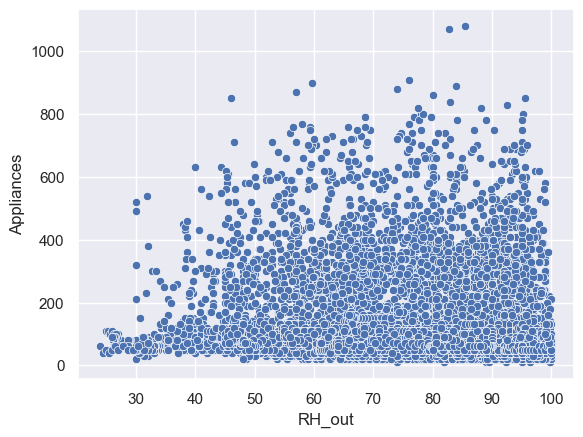

In [220]:
sns.scatterplot(x='RH_out',y='Appliances',data=df)

#### Key Findings
- Pearson correlation: −0.1523 — indicates a weak negative linear relationship between outdoor relative humidity and appliance energy consumption.
- Spearman correlation: −0.2691 — indicates a somewhat stronger negative monotonic relationship, suggesting that consumption generally tends to decrease as outdoor humidity increases, although the pattern is not consistent.
- Grouped means: Average consumption peaks at approximately 155.05 Wh in the 39.2–46.8% humidity interval. It generally declines at higher humidity levels, reaching around 82–83 Wh in the highest two intervals.
- Grouped medians: The median falls from 100 Wh in the 39.2–46.8% interval to 60 Wh in the two highest humidity intervals.
- Variability and outliers: Standard deviations are substantial, and maximum consumption reaches 1,080 Wh in the 84.8–92.4% interval. This indicates that high humidity does not prevent occasional high-energy-consumption events.
- Uneven sample sizes: The lowest humidity intervals contain relatively few observations, so their averages may be less reliable than those of the more populated intervals.

#### Appliances vs Windspeed

In [224]:
print('Pearson:',df['Appliances'].corr(df['Windspeed']))
print('Spearman:',df['Appliances'].corr(df['Windspeed'],method='spearman'))

df.groupby(
    pd.cut(df['Windspeed'], bins=10, include_lowest=True),
    observed=True
)['Appliances'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)


Pearson: 0.0871221059123584
Spearman: 0.11231964716741033


,count,mean,median,std,min,max
Windspeed,,,,,,
"(-0.015, 1.4]",2753,82.517254,60.0,88.147635,10,1070
"(1.4, 2.8]",4156,83.645332,60.0,82.790201,10,880
"(2.8, 4.2]",5232,97.719801,60.0,98.950618,10,1080
"(4.2, 5.6]",2784,111.993534,70.0,113.597046,20,870
"(5.6, 7.0]",2468,121.734198,70.0,130.768329,10,910
"(7.0, 8.4]",1008,101.805556,60.0,104.570403,20,710
"(8.4, 9.8]",792,95.404040,60.0,97.041383,10,660
"(9.8, 11.2]",427,92.786885,60.0,104.364651,20,710
"(11.2, 12.6]",79,117.088608,50.0,139.983075,20,750


<Axes: xlabel='Windspeed', ylabel='Appliances'>

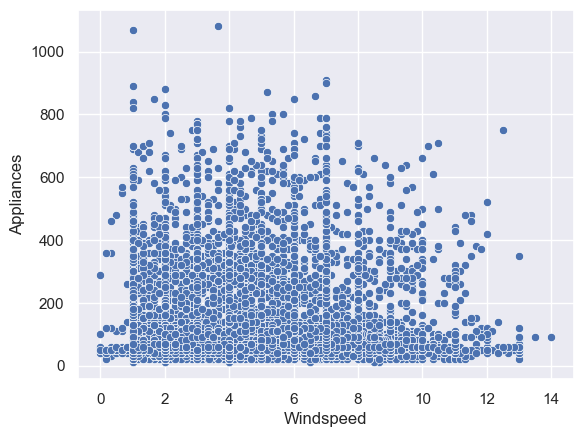

In [226]:
sns.scatterplot(x='Windspeed',y='Appliances',data=df)

#### Key Findings
- Pearson correlation: 0.0871 — indicates a very weak positive linear relationship between windspeed and appliance energy consumption.
- Spearman correlation: 0.1123 — indicates a very weak positive monotonic relationship. Both correlation values suggest that windspeed has a limited standalone association with energy consumption.
- Grouped means: Average consumption increases from approximately 82.52 Wh at the lowest windspeed interval to 121.73 Wh at 5.6–7.0, then generally declines as windspeed increases further.
- Grouped medians: Median consumption remains mostly between 50 and 70 Wh across all intervals, indicating that typical consumption does not change substantially with windspeed.
- High variability: Standard deviations are large relative to the means, and maximum consumption reaches 1,080 Wh in the 2.8–4.2 interval. This suggests that energy consumption varies considerably at similar windspeed levels.
- Uneven sample sizes: The final two intervals contain only 79 and 36 observations, respectively, so their means are less reliable and should be interpreted cautiously.

#### Appliances vs Visibility

In [234]:
print('Pearson:',df['Appliances'].corr(df['Visibility']))
print('Spearman:',df['Appliances'].corr(df['Visibility'],method='spearman'))

df.groupby(
    pd.cut(df['Visibility'], bins=10, include_lowest=True),
    observed=True
)['Appliances'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)


Pearson: 0.0002303578554723239
Spearman: -0.0035457428298263875


,count,mean,median,std,min,max
Visibility,,,,,,
"(0.934, 7.5]",92,51.630435,50.0,20.927776,20,180
"(7.5, 14.0]",91,52.527473,50.0,33.319777,10,280
"(14.0, 20.5]",348,71.149425,50.0,58.638251,20,480
"(20.5, 27.0]",3122,88.978219,60.0,93.243798,20,780
"(27.0, 33.5]",2790,103.465950,60.0,106.401393,10,800
"(33.5, 40.0]",9199,106.131101,70.0,108.668234,10,1080
"(40.0, 46.5]",648,83.287037,60.0,90.142414,10,800
"(46.5, 53.0]",737,85.169607,60.0,94.664767,20,850
"(53.0, 59.5]",767,86.597132,60.0,91.217601,20,710


<Axes: xlabel='Visibility', ylabel='Appliances'>

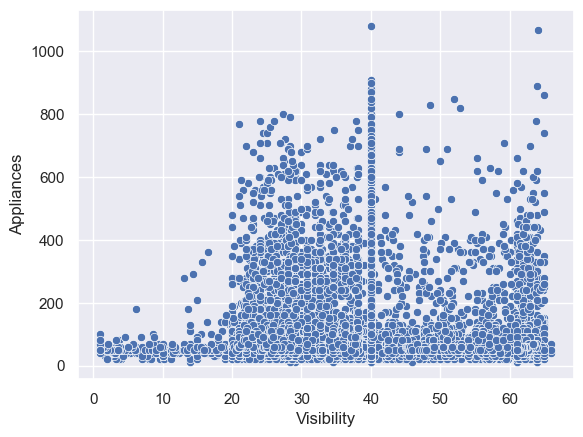

In [236]:
sns.scatterplot(x='Visibility',y='Appliances',data=df)

#### Key Findings
- Pearson correlation: 0.00023 — indicates virtually no linear relationship between visibility and appliance energy consumption.
- Spearman correlation: −0.00355 — indicates virtually no monotonic relationship. Both correlation coefficients are extremely close to zero.
- Grouped means: Average consumption rises from approximately 51.6 Wh in the lowest visibility interval to 106.1 Wh in the 33.5–40.0 interval, then declines and fluctuates around 83–87 Wh in the higher intervals. This suggests a non-linear pattern in the grouped averages, despite the near-zero overall correlations.
- Grouped medians: The median is mostly between 50 and 70 Wh, showing relatively little change in typical consumption across visibility intervals.
- High variability: Standard deviations are substantial in many intervals, and maximum consumption reaches 1,080 Wh in the 33.5–40.0 interval. Consumption therefore varies considerably even at similar visibility levels.
- Uneven sample sizes: The interval counts range from 91 to 9,199 observations. The smaller groups may produce less stable averages, while the large 33.5–40.0 interval dominates the dataset.

#### Appliances vs Tdewpoint

In [240]:
print('Pearson:',df['Appliances'].corr(df['Tdewpoint']))
print('Spearman:',df['Appliances'].corr(df['Tdewpoint'],method='spearman'))

df.groupby(
    pd.cut(df['Tdewpoint'], bins=10, include_lowest=True),
    observed=True
)['Appliances'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)


Pearson: 0.015353010487472682
Spearman: 0.07522059809100666


,count,mean,median,std,min,max
Tdewpoint,,,,,,
"(-6.623, -4.39]",450,83.844444,50.0,114.302856,10,740
"(-4.39, -2.18]",908,91.321586,60.0,112.774052,20,1070
"(-2.18, 0.03]",2017,106.470005,60.0,115.089394,20,1080
"(0.03, 2.24]",4265,95.008206,60.0,95.274887,10,910
"(2.24, 4.45]",4057,95.753019,60.0,97.426608,10,880
"(4.45, 6.66]",3201,98.250547,60.0,104.346483,10,870
"(6.66, 8.87]",2573,102.312476,60.0,109.271483,10,900
"(8.87, 11.08]",1226,90.970636,60.0,82.957304,10,710
"(11.08, 13.29]",577,110.606586,70.0,114.979525,30,820


<Axes: xlabel='Tdewpoint', ylabel='Appliances'>

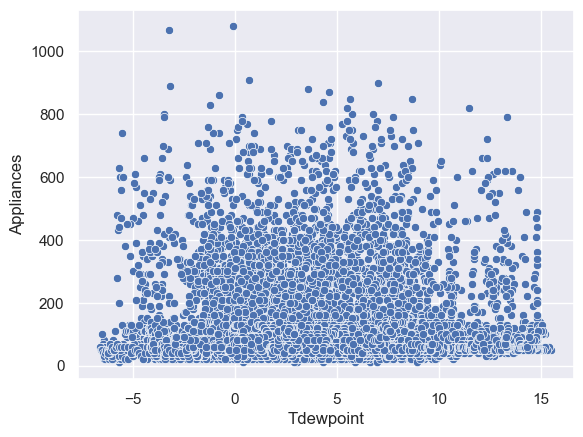

In [242]:
sns.scatterplot(x='Tdewpoint',y='Appliances',data=df)

#### Bivariate Analysis: Tdewpoint vs Appliances
Key Findings
- Pearson correlation: 0.0154 — indicates virtually no linear relationship between dew point temperature and appliance energy consumption.
- Spearman correlation: 0.0752 — indicates a very weak positive monotonic relationship. The association remains negligible overall.
- Grouped means: Average consumption fluctuates across dew point intervals, from 83.84 Wh in the lowest interval to 110.61 Wh in the 11.08–13.29 interval. There is no consistent increasing or decreasing trend.
- Grouped medians: Median consumption remains at 60 Wh across most intervals, with a small increase to 70 Wh in the 11.08–13.29 interval.
- High variability: Standard deviations range from approximately 83 to 115 Wh in most groups, and maximum consumption reaches 1,080 Wh. Appliance consumption varies substantially even at similar dew point temperatures.
- Uneven sample sizes: Counts range from 450 to 4,265 observations. The averages in the smaller groups should be interpreted more cautiously.

In [245]:
df.columns

Index(['date', 'Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3',
       'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8',
       'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed',
       'Visibility', 'Tdewpoint', 'rv1', 'rv2'],
      dtype='object')

#### rv1 vs Appliances

In [252]:
print('Pearson:',df['Appliances'].corr(df['rv1']))
print('Spearman:',df['Appliances'].corr(df['rv1'],method='spearman'))

df.groupby(
    pd.cut(df['rv1'], bins=10, include_lowest=True),
    observed=True
)['Appliances'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)


Pearson: -0.011144917533634445
Spearman: -0.009288598432578532


,count,mean,median,std,min,max
rv1,,,,,,
"(-0.0457, 5.004]",2024,98.246047,60.0,105.607190,10,890
"(5.004, 10.004]",1932,99.301242,60.0,102.957701,10,760
"(10.004, 15.003]",2018,96.828543,60.0,100.730359,10,1070
"(15.003, 20.002]",1953,100.834613,60.0,107.666521,10,910
"(20.002, 25.001]",1984,98.034274,60.0,103.009025,10,850
"(25.001, 30.0]",1963,101.456954,60.0,109.998687,10,1080
"(30.0, 34.999]",1932,97.774327,60.0,101.946945,20,800
"(34.999, 39.998]",1919,93.001563,60.0,91.875122,20,800
"(39.998, 44.997]",1963,93.020886,60.0,96.843627,20,860


<Axes: xlabel='rv1', ylabel='Appliances'>

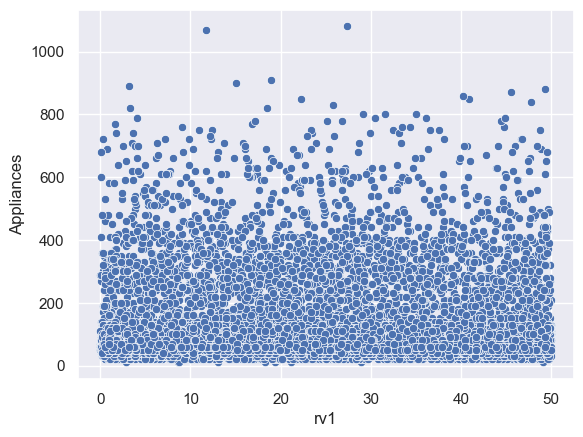

In [250]:
sns.scatterplot(x='rv1',y='Appliances',data=df)

#### Bivariate Analysis: rv1 vs Appliances
Key Findings
- Pearson correlation: −0.0111 — indicates virtually no linear relationship between rv1 and appliance energy consumption.
- Spearman correlation: −0.0093 — indicates virtually no monotonic relationship. Both coefficients are extremely close to zero.
- Grouped means: Average consumption fluctuates slightly between approximately 93.00 Wh and 101.46 Wh across the ten intervals, with no consistent increasing or decreasing trend.
- Grouped medians: The median remains exactly 60 Wh in every interval, indicating no change in typical consumption across the groups.
- Variability: Standard deviations range from approximately 91.88 to 110.00 Wh, and maximum consumption reaches 1,080 Wh. This variation appears unrelated to changes in rv1.
- Feature interpretation: rv1 is a randomized variable included in the original dataset, rather than a meaningful environmental measurement. Its near-zero correlations are consistent with that role.
EDA Summary

#### Appliances vs rv2

In [256]:
print('Pearson:',df['Appliances'].corr(df['rv2']))
print('Spearman:',df['Appliances'].corr(df['rv2'],method='spearman'))

df.groupby(
    pd.cut(df['rv2'], bins=10, include_lowest=True),
    observed=True
)['Appliances'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)


Pearson: -0.011144917533634445
Spearman: -0.009288598432578532


,count,mean,median,std,min,max
rv2,,,,,,
"(-0.0457, 5.004]",2024,98.246047,60.0,105.607190,10,890
"(5.004, 10.004]",1932,99.301242,60.0,102.957701,10,760
"(10.004, 15.003]",2018,96.828543,60.0,100.730359,10,1070
"(15.003, 20.002]",1953,100.834613,60.0,107.666521,10,910
"(20.002, 25.001]",1984,98.034274,60.0,103.009025,10,850
"(25.001, 30.0]",1963,101.456954,60.0,109.998687,10,1080
"(30.0, 34.999]",1932,97.774327,60.0,101.946945,20,800
"(34.999, 39.998]",1919,93.001563,60.0,91.875122,20,800
"(39.998, 44.997]",1963,93.020886,60.0,96.843627,20,860


<Axes: xlabel='rv2', ylabel='Appliances'>

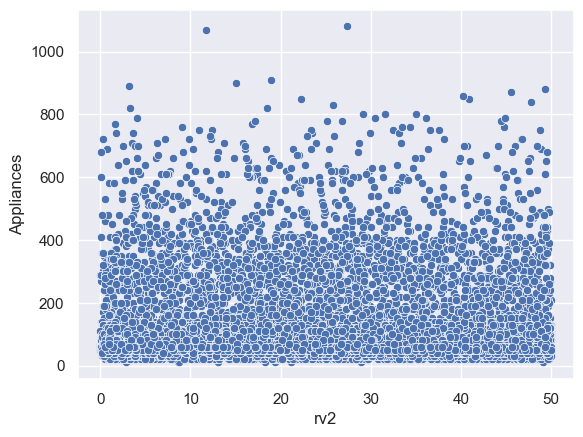

In [258]:
sns.scatterplot(x='rv2',y='Appliances',data=df)

#### Bivariate Analysis: rv2 vs Appliances
Key Findings
- Pearson correlation: −0.0111 — indicates virtually no linear relationship between rv2 and appliance energy consumption.
- Spearman correlation: −0.0093 — indicates virtually no monotonic relationship.
- Grouped means: Average consumption fluctuates between approximately 93.00 Wh and 101.46 Wh, without a consistent trend.
- Grouped medians: Every interval has a median of 60 Wh, suggesting no meaningful change in typical consumption across the groups.
- Variability: Standard deviations remain high, ranging from approximately 91.88 to 110.00 Wh. Maximum consumption reaches 1,080 Wh, but these high values do not correspond to a consistent rv2 pattern.
- Important data-quality check: The correlations and every grouped statistic you provided are identical to those for rv1. Since rv1 and rv2 are separate randomized variables, verify that the calculations actually reference rv2 and that the two columns are not duplicates.
EDA Summary
The reported results suggest that rv2 has virtually no association with appliance energy consumption. However, because every statistic matches the rv1 results exactly, we should verify the calculations before treating this as a confirmed finding. The original dataset includes randomized variables intended for data-quality and reproducibility purposes, not as meaningful environmental predictors. If confirmed as the original randomized feature, rv2 should generally be excluded from the forecasting model.

# Bivariate Analysis Report: Appliance Energy Forecasting

**Project:** Appliance Energy Forecasting  
**Dataset:** UCI Appliances Energy Prediction  
**Dataset size:** 19,735 observations and 29 columns  
**Target variable:** `Appliances`  
**Forecasting objective:** Predict appliance energy consumption at the next 10-minute interval using information available at forecast time.

---

## 1. Executive Summary

Bivariate analysis was conducted to investigate the relationship between appliance energy consumption and individual environmental, room-level, and other numerical features. The analysis combined Pearson correlation, Spearman correlation, and grouped descriptive statistics, including mean, median, standard deviation, minimum, maximum, and observation count.

The findings indicate that **no individual feature examined has a strong linear relationship with appliance energy consumption**. The strongest observed associations were between consumption and lighting usage (`lights`), outdoor relative humidity (`RH_out`), living-room temperature (`T2`), and temperature outside the building (`T6`).

Lighting showed the strongest positive rank-based association, while outdoor relative humidity showed the strongest negative rank-based association among the features examined. Several room temperature and humidity sensors exhibited weak relationships with the target, while visibility, dew point, atmospheric pressure, and the randomized variables showed negligible or very weak associations.

Grouped statistics revealed patterns that simple correlations may not fully describe. In several cases, average consumption increased over lower or intermediate feature ranges and then declined or fluctuated at higher values. However, considerable variation in consumption remained within nearly every group.

These results suggest that appliance energy demand is influenced by a combination of environmental conditions, occupant behavior, appliance usage patterns, and potentially time-dependent effects. The next analytical stage should investigate interactions, multicollinearity, time-related patterns, and possible nonlinear relationships.

## 2. Objectives of the Analysis

The bivariate analysis aimed to:

1. Measure the direction and strength of the relationship between each numerical predictor and `Appliances`.
2. Compare linear relationships with rank-based monotonic relationships.
3. Identify trends and irregular patterns using grouped descriptive statistics.
4. Assess which features may deserve further investigation during model development.
5. Identify potentially redundant predictors and features that may not provide meaningful information.
6. Establish a sound basis for multivariate analysis and subsequent forecasting-model development.

## 3. Methodology

### 3.1 Pearson correlation

Pearson's correlation coefficient measures the strength and direction of a linear relationship between two numerical variables.

- Values near +1 indicate a strong positive linear relationship.
- Values near −1 indicate a strong negative linear relationship.
- Values near 0 indicate little or no linear relationship.

Pearson correlation is useful for identifying features whose values tend to change linearly with appliance energy consumption. However, a low Pearson coefficient does not rule out nonlinear relationships.

### 3.2 Spearman correlation

Spearman's rank correlation measures the strength and direction of a monotonic relationship. It operates on ranked values rather than the original measurements.

A monotonic relationship means that one variable tends to increase or decrease as the other changes, although the rate of change need not be constant.

Comparing Pearson and Spearman coefficients helps identify whether a relationship is predominantly linear, rank-based, or weak under both measures.

For example, a Spearman coefficient with a larger absolute value than the corresponding Pearson coefficient may indicate a monotonic relationship that is not well represented by a straight line. It does not, by itself, prove that the relationship is nonlinear.

### 3.3 Grouped descriptive statistics

Features were divided into ten intervals using `pd.cut()`. For each interval, the following statistics were calculated:

- **Count:** Number of observations in the interval.
- **Mean:** Average appliance energy consumption.
- **Median:** Middle consumption value.
- **Standard deviation:** Degree of variation in consumption.
- **Minimum and maximum:** Lowest and highest observed consumption.

Grouping helps reveal changes in average consumption across different feature ranges. Nevertheless, binning loses some information about individual observations, and results depend partly on the chosen interval boundaries.

### 3.4 Important interpretation distinction

This report discusses the **strength of observed associations**, not formal statistical significance. P-values, confidence intervals, and hypothesis tests were not calculated as part of the analysis summarized here.

A correlation coefficient should therefore not be described as statistically significant or insignificant on the basis of its magnitude alone.

## 4. Summary of Correlation Results

The following table consolidates the reported Pearson and Spearman coefficients.

| Feature | Pearson | Spearman | Interpretation |
|---|---:|---:|---|
| `lights` | +0.1973 | +0.3024 | Weak positive association; strongest rank-based relationship |
| `RH_out` | −0.1523 | −0.2691 | Weak negative association |
| `T2` | +0.1201 | +0.3051 | Weak positive linear relationship; stronger rank-based association |
| `T6` | +0.1176 | +0.2425 | Weak positive association |
| `Windspeed` | +0.0871 | +0.1123 | Very weak positive association |
| `RH_8` | −0.0940 | −0.2172 | Weak negative association |
| `T_out` | +0.0992 | +0.2155 | Weak positive association |
| `T3` | +0.0851 | +0.2169 | Weak positive association |
| `RH_6` | −0.0832 | −0.2297 | Weak negative association |
| `RH_1` | +0.0860 | +0.0605 | Very weak positive linear association |
| `T1` | +0.0554 | +0.2440 | Weak positive rank-based association |
| `T7` | +0.0258 | +0.1819 | Very weak linear; weak positive rank-based association |
| `T8` | +0.0396 | +0.2361 | Very weak linear; weak positive rank-based association |
| `T9` | +0.0100 | +0.1670 | Virtually no linear relationship; weak positive rank-based association |
| `RH_2` | −0.0605 | −0.1197 | Very weak negative association |
| `RH_3` | +0.0363 | −0.0571 | Negligible association under both measures |
| `RH_4` | +0.0170 | −0.0202 | Negligible association under both measures |
| `RH_5` | +0.0070 | −0.0449 | Negligible association under both measures |
| `RH_7` | −0.0556 | −0.1194 | Weak negative association |
| `RH_9` | −0.0515 | −0.1646 | Weak negative association |
| `Visibility` | +0.0002 | −0.0035 | Virtually no association |
| `Tdewpoint` | +0.0154 | +0.0752 | Virtually no linear; very weak positive rank-based association |
| `Press_mm_hg` | −0.0349 | −0.0962 | Negligible linear; very weak negative rank-based association |
| `rv1` | −0.0111 | −0.0093 | Virtually no association |
| `rv2` | −0.0111 | −0.0093 | Reported results require verification |
| `T4` | +0.0403 | +0.2072 | Negligible linear; weak positive rank-based association |
| `T5` | Reported values duplicated `T4` | Reported values duplicated `T4` | Verify calculations before drawing a conclusion |

**Note:** Correlations are rounded to four decimal places. The `T5` values were reported as identical to `T4`, so they should not be treated as confirmed until recalculated. The `rv2` grouped statistics and correlations were also identical to those reported for `rv1`; the calculations should be verified before finalizing the feature assessment.

## 5. Detailed Findings by Feature Group

### 5.1 Lighting: `lights`

**Reported correlations:** Pearson = +0.1973; Spearman = +0.3024.

Lighting exhibited the strongest positive rank-based association among the features summarized here.

The grouped means generally increased with higher lighting levels:

- At `lights = 0`, mean consumption was approximately 86.58 Wh.
- At `lights = 10`, mean consumption increased to approximately 129.04 Wh.
- At `lights = 20`, mean consumption was approximately 136.43 Wh.
- At `lights = 30`, mean consumption reached approximately 150.21 Wh.
- At `lights = 40`, mean consumption was approximately 182.34 Wh.

The relationship was not perfectly increasing at the highest lighting levels. More importantly, the upper groups contained very few observations: the groups for 50, 60, and 70 had 9, 1, and 1 observations, respectively.

**Interpretation:** Higher lighting usage tends to coincide with higher appliance consumption. This could reflect periods of greater household activity, occupancy, or simultaneous use of multiple electrical devices. However, the relationship is associative, and lighting may partly act as a proxy for human activity rather than directly explaining all changes in appliance energy use.

**Implication:** Retain `lights` for further investigation, while checking its distribution and relationship with time of day and other predictors.

### 5.2 Room and outdoor temperatures

The temperature features include `T1` through `T9`, as well as `T_out` and `T6`, which represents the temperature outside the building in this dataset.

The overall pattern was one of weak positive associations, with some differences between Pearson and Spearman coefficients.

#### Living-room temperature: `T2`

Pearson correlation was +0.1201, while Spearman correlation was +0.3051.

This difference suggests that the rank-based association is stronger than the linear relationship. Grouped consumption means generally rose across the lower-to-higher temperature ranges but fluctuated rather than increasing uniformly.

#### Outdoor temperature: `T_out`

Pearson correlation was +0.0992 and Spearman correlation was +0.2155.

Grouped means and medians broadly increased from colder to moderate or warmer temperatures, although the pattern fluctuated at the warmest end.

#### Other room temperatures

`T1`, `T3`, `T4`, `T6`, `T7`, `T8`, and `T9` showed varying degrees of weak positive association. Some, including `T1`, `T7`, `T8`, and `T9`, had much larger Spearman than Pearson coefficients, suggesting that their relationships with consumption may not be well summarized by a straight line.

For `T6`, the reported coefficients were +0.1176 and +0.2425, respectively. Its grouped means rose through warmer intervals before declining in some of the warmest groups.

`T5` requires verification because its reported correlations were identical to those of `T4`.

**Interpretation:** Temperature alone has limited linear explanatory power, but rank-based patterns and grouped trends indicate that some temperature variables may still carry useful information. Indoor and outdoor temperatures may also interact with one another, time of day, and household behavior.

**Implication:** Do not discard temperature sensors solely because their individual correlations are weak. Investigate their interrelationships and incremental predictive value in multivariate analysis.

### 5.3 Relative humidity: `RH_1` through `RH_9` and `RH_out`

Humidity features displayed a mixture of weak positive, weak negative, and negligible relationships with appliance consumption.

#### Outdoor relative humidity: `RH_out`

Pearson correlation was −0.1523 and Spearman correlation was −0.2691.

The grouped means peaked at approximately 155.05 Wh in the 39.2–46.8% humidity interval, then generally declined toward approximately 82–83 Wh in the two highest humidity intervals. The medians also declined from 100 Wh in the peak interval to 60 Wh in the highest intervals.

This supports a broad negative association at higher humidity levels, although the intermediate intervals did not follow a perfectly consistent trend.

#### Humidity sensors with negative rank-based associations

- `RH_6`: Pearson = −0.0832; Spearman = −0.2297.
- `RH_8`: Pearson = −0.0940; Spearman = −0.2172.
- `RH_9`: Pearson = −0.0515; Spearman = −0.1646.
- `RH_2`: Pearson = −0.0605; Spearman = −0.1197.
- `RH_7`: Pearson = −0.0556; Spearman = −0.1194.

These results indicate weak negative relationships, with some showing more noticeable rank-based associations than linear ones.

`RH_6` showed declining grouped means through the middle humidity intervals, followed by fluctuations at higher values. `RH_8` displayed a broad decline in grouped means and medians as humidity increased, although substantial variation remained within groups.

#### Humidity sensors with negligible relationships

`RH_3`, `RH_4`, and `RH_5` showed correlations close to zero under both measures. `RH_1` showed a very weak positive linear association, but its Spearman coefficient was even closer to zero.

**Interpretation:** Outdoor humidity has a more noticeable association with consumption than most individual indoor humidity sensors. Nevertheless, the humidity variables should be considered jointly with temperature, time, and other predictors. Some sensors may contain overlapping information.

**Implication:** Investigate correlations among humidity sensors and evaluate whether selected sensors provide distinct information during modeling.

### 5.4 Windspeed

Pearson correlation was +0.0871 and Spearman correlation was +0.1123.

Grouped means increased from approximately 82.52 Wh in the lowest interval to 121.73 Wh in the 5.6–7.0 interval, then generally declined at higher windspeed values. Median consumption remained mostly between 50 and 70 Wh.

The last two intervals contained only 79 and 36 observations, making their means less stable.

**Interpretation:** Windspeed has a very weak positive association with appliance energy consumption. The grouped averages do not indicate a consistent increase over the entire range.

**Implication:** Retain it for evaluation rather than assuming it is either useful or useless based on correlation alone.

### 5.5 Visibility

Pearson correlation was +0.0002 and Spearman correlation was −0.0035.

Grouped means increased from approximately 51.63 Wh in the lowest interval to 106.13 Wh in the 33.5–40.0 interval, then declined and fluctuated around 83–87 Wh in several higher intervals.

Despite this grouped pattern, both overall correlations were effectively zero. Median consumption remained mostly between 50 and 70 Wh.

**Interpretation:** Visibility has virtually no overall linear or monotonic relationship with consumption. The grouped averages suggest that some interval-level differences exist, but they do not establish a stable or general relationship.

**Implication:** Visibility appears to have low standalone relevance. Its incremental value should be checked during model evaluation if retaining all original predictors is practical.

### 5.6 Dew point temperature: `Tdewpoint`

Pearson correlation was +0.0154 and Spearman correlation was +0.0752.

Grouped means fluctuated across the dew point intervals, from approximately 83.84 Wh in the lowest interval to 110.61 Wh in the 11.08–13.29 interval. The medians remained at 60 Wh across most groups.

**Interpretation:** Dew point has virtually no linear association and only a very weak positive rank-based association with appliance consumption.

**Implication:** Its individual predictive value appears limited, although its relationship with other temperature and humidity variables may warrant checking before removal.

### 5.7 Atmospheric pressure: `Press_mm_hg`

Pearson correlation was −0.0349 and Spearman correlation was −0.0962.

Grouped means fluctuated without a consistent trend, while medians were mostly stable at 60 Wh.

**Interpretation:** Atmospheric pressure has negligible linear association and only a very weak negative rank-based association with appliance consumption.

**Implication:** It is a lower-priority feature for investigation, but final exclusion should be based on validation results rather than correlation alone.

### 5.8 Randomized variables: `rv1` and `rv2`

For `rv1`, Pearson correlation was −0.0111 and Spearman correlation was −0.0093. Grouped means fluctuated narrowly between approximately 93.00 and 101.46 Wh, while every group's median was 60 Wh.

The reported `rv2` results were identical, including all grouped statistics.

**Interpretation:** The reported statistics show virtually no relationship between these variables and appliance consumption. The original dataset includes randomized variables rather than meaningful environmental measurements.

**Data-quality caution:** Since all reported `rv2` statistics matched `rv1` exactly, verify that the `rv2` calculations reference the correct column and that the two columns are not duplicated or accidentally reused in the notebook.

**Implication:** If verified as the original randomized features, `rv1` and `rv2` would generally be excluded from the forecasting model.

## 6. Major Trends and Patterns Captured

### Pattern 1: No single predictor dominates

The largest absolute Pearson coefficient in the summarized results was approximately 0.1973 for `lights`. The strongest absolute Spearman coefficients were approximately 0.3051 for `T2` and 0.3024 for `lights`.

These magnitudes indicate weak individual associations rather than strong standalone relationships.

This does not mean the dataset lacks predictive information. Several weak predictors can contribute useful combined information, and nonlinear models may capture patterns that individual correlation coefficients miss.

### Pattern 2: Rank-based relationships can be stronger than linear relationships

Several variables displayed noticeably larger absolute Spearman coefficients than Pearson coefficients, including `T2`, `T1`, `T7`, `T8`, `T9`, `RH_6`, and `RH_8`.

This suggests that a straight-line relationship may not fully summarize how these features relate to consumption.

However, a difference between Pearson and Spearman does not conclusively establish nonlinearity. Scatterplots, smooth trend lines, and conditional analyses would be needed to investigate the shape of these relationships.

### Pattern 3: Grouped means fluctuate more than medians

Across many features, group means varied more visibly than medians. Median appliance consumption frequently remained around 60 Wh, while some group means exceeded 100 Wh or even 150 Wh.

This is consistent with a right-skewed target distribution in which occasional high-consumption observations raise averages. The earlier univariate analysis also identified substantial right skew and high-consumption extremes.

As a result, reporting both mean and median was useful: the mean captures changes in average energy demand, while the median provides a view of more typical consumption.

### Pattern 4: High within-group variability is common

Standard deviations were substantial across many temperature, humidity, lighting, and weather intervals. Some groups also contained observations with very high maximum consumption.

This means that similar environmental conditions can correspond to quite different appliance energy usage. Household activity, appliance schedules, time of day, and other unobserved factors may help explain this variability.

### Pattern 5: Uneven group sizes affect interpretation

Several features had sparsely populated extreme intervals. For example, the highest lighting groups contained only one or a few observations, while the highest windspeed intervals also had small counts.

Means calculated from small groups can be unstable and may change considerably with a few observations. Conclusions should therefore be based on both the group count and the observed pattern rather than the mean alone.

### Pattern 6: Environmental features may contain overlapping information

Temperature sensors and humidity sensors measure related conditions. Outdoor temperature, indoor temperatures, dew point, and relative humidity may be correlated with one another.

Consequently, the contribution of an individual feature can differ when other predictors are included. A variable with a weak bivariate correlation may still help a multivariable model, while a strongly correlated sensor may add little new information if another sensor already captures the same pattern.

## 7. Feature Relevance Assessment

Based on the reported bivariate evidence, the features can be grouped into provisional investigation priorities.

| Priority | Features | Reason |
|---|---|---|
| Higher priority for further investigation | `lights`, `RH_out`, `T2`, `T6`, `T_out`, `RH_6`, `RH_8`, `T1`, `T3`, `T8` | Comparatively stronger associations under at least one correlation measure |
| Secondary investigation | `Windspeed`, `T7`, `T9`, `RH_2`, `RH_7`, `RH_9`, `RH_1` | Weak or very weak associations that may still add information jointly |
| Lower standalone priority | `Visibility`, `Tdewpoint`, `Press_mm_hg`, `RH_3`, `RH_4`, `RH_5` | Correlations are generally close to zero |
| Verify before modeling | `T5`, `rv1`, `rv2` | Reported duplication or randomized-variable concerns |

These are **investigation priorities, not final feature-selection decisions**. A definitive feature ranking would require multivariate analysis and time-aware model validation.

## 8. Limitations of the Bivariate Analysis

Several limitations should be acknowledged.

1. **Correlation does not establish causation.** A relationship between a sensor reading and appliance consumption does not demonstrate that the sensor reading causes the consumption change.

2. **Bivariate relationships do not account for confounding.** A feature may appear associated with consumption because both variables change with time of day or another underlying factor.

3. **Correlation can miss complex patterns.** Pearson correlation focuses on linear association, while Spearman focuses on monotonic association. Neither fully captures every possible nonlinear relationship.

4. **Binning loses detail.** Dividing features into ten intervals makes trends easier to inspect but hides variation within each interval and makes results sensitive to interval boundaries.

5. **Extreme observations affect means and ranges.** High-consumption events can raise group means and standard deviations. Medians help provide a complementary view.

6. **Small groups have less stable summaries.** Means from intervals with few observations should be treated cautiously.

7. **No formal significance testing was performed.** The analysis establishes observed correlation magnitudes, not statistical significance or confidence intervals.

8. **Feature importance is not yet established.** Bivariate correlations cannot determine which variables will matter most in a properly validated forecasting model.

9. **Potential data-quality issues remain.** The duplicated `T5` correlation values and identical `rv1`/`rv2` results should be checked before the findings are finalized.

10. **Forecasting requires temporal validation.** Random train-test splitting can produce overly optimistic results when observations from similar or neighboring periods appear in both sets. The eventual forecasting evaluation should respect time ordering and ensure that predictors are available at the forecast origin.

## 9. Recommendations for the Next Stage

The following steps are recommended before finalizing the model features.

### 9.1 Multivariate correlation analysis

Create a correlation heatmap for numerical variables. Focus on:

- Relationships among temperature sensors.
- Relationships among humidity sensors.
- Relationships between indoor and outdoor environmental measurements.
- Features that are strongly correlated with one another.

This will help identify potential redundancy and guide further investigation.

### 9.2 Investigate temporal patterns

Examine consumption by hour of day, weekday, and other useful time periods. Household appliance usage may be strongly time-dependent even when individual environmental correlations are weak.

For forecasting, these variables must be derived from timestamps available at prediction time.

### 9.3 Explore multivariable and nonlinear relationships

Use selected scatterplots, grouped comparisons, and other suitable visualizations to investigate whether the relationship between temperature, humidity, and consumption changes depending on other conditions.

### 9.4 Verify data-quality concerns

Recalculate the correlations for `T5` and `rv2` directly from the intended columns. Confirm that `rv1` and `rv2` are distinct columns and that no notebook cells accidentally reused earlier outputs.

### 9.5 Evaluate predictive contribution using time-aware validation

After the exploratory stages, compare sensible baseline and machine-learning models using a chronological split or time-series validation strategy. Evaluate predictions on the original consumption scale and compare models using